# Dataset Loading and Inspection

In [1]:
import os
import json
import pandas as pd
from collections import Counter

dataset_path = r"E:\4079\Dataset"

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
audio_extensions = {".wav", ".mp3", ".flac", ".ogg", ".m4a", ".aac"}

image_files = []
audio_files = []
csv_files = []
jsonl_files = []

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        ext = os.path.splitext(file)[1].lower()
        full_path = os.path.join(root, file)

        if ext in image_extensions:
            image_files.append(full_path)
        elif ext in audio_extensions:
            audio_files.append(full_path)
        elif ext == ".csv":
            csv_files.append(full_path)
        elif ext == ".jsonl":
            jsonl_files.append(full_path)
print("=" * 100)
print("TOTAL NUMBER OF IMAGES")
print("=" * 100)
print(f"Total Images: {len(image_files)}")
print("Image Formats:")
for fmt, count in sorted(Counter(os.path.splitext(f)[1].lower() for f in image_files).items()):
    print(f"{fmt}: {count}")
print("\n")
print("=" * 100)
print("TOTAL NUMBER OF AUDIOS")
print("=" * 100)
print(f"Total Audios: {len(audio_files)}")
print("Audio Formats:")
for fmt, count in sorted(Counter(os.path.splitext(f)[1].lower() for f in audio_files).items()):
    print(f"{fmt}: {count}")
print("\n")
print("=" * 100)
print("CSV FILE INSPECTION")
print("=" * 100)
if csv_files:
    for csv_path in csv_files:
        try:
            df = pd.read_csv(csv_path)
            print(f"Shape: {df.shape}")
            print("\nFirst 5 rows of CSV Dataset:")
            print(df.head(5))
        except Exception as e:
            print(f"Error reading CSV: {e}")
else:
    print("No CSV files found.")
print("\n")
print("=" * 100)
print("TEXT.JSONL INSPECTION")
print("=" * 100)

text_jsonl_files = [
    f for f in jsonl_files
    if os.path.basename(f).lower() == "text.jsonl"
]

if text_jsonl_files:
    for jsonl_path in text_jsonl_files:
        try:
            with open(jsonl_path, "r", encoding="utf-8") as file:
                for line_number, line in enumerate(file, start=1):
                    line = line.strip()
                    if line:
                        try:
                            data = json.loads(line)
                            print(f"\nRecord {line_number}:")
                            print(json.dumps(data, indent=4, ensure_ascii=False))
                        except json.JSONDecodeError:
                            print(f"\nRecord {line_number}:")
                            print(line)
        except Exception as e:
            print(f"Error reading JSONL: {e}")
else:
    print("text.jsonl not found.")

print("DATASET INSPECTION COMPLETED")

TOTAL NUMBER OF IMAGES
Total Images: 6841
Image Formats:
.jpg: 6841


TOTAL NUMBER OF AUDIOS
Total Audios: 6841
Audio Formats:
.wav: 6841


CSV FILE INSPECTION
Shape: (6841, 13)

First 5 rows of CSV Dataset:
    Image_ID       Audio_ID  Image_Width  Image_Height  Image_Size_KB  \
0  1 (1).jpg  Audio (1).wav          105           215          3.641   
1  1 (2).jpg  Audio (2).wav          105           193          3.755   
2  1 (3).jpg  Audio (3).wav          105           192          3.689   
3  1 (4).jpg  Audio (4).wav          105           386          2.895   
4  1 (5).jpg  Audio (5).wav          105           505          2.540   

   Audio_Duration  Audio_Sample_Rate  Audio_Channels  Audio_Size_KB  \
0           8.770              22050               1        755.447   
1           7.483              22050               1        644.588   
2           9.109              22050               1        784.666   
3           7.443              22050               1        641.150  

# Data Partioning - 70:30

In [2]:
import os
import json
import shutil
import random
import pandas as pd
from sklearn.model_selection import train_test_split

random.seed(42)

SOURCE_DIR = r"E:\4079\Dataset"
OUTPUT_DIR = r"E:\4079\Output\Data Split"

IMAGE_DIR = os.path.join(SOURCE_DIR, "Images")
AUDIO_DIR = os.path.join(SOURCE_DIR, "Audio")
CSV_PATH = os.path.join(SOURCE_DIR, "Japanese_Multimodal_Dataset.csv")
TEXT_PATH = os.path.join(SOURCE_DIR, "text.jsonl")

OUTPUT_IMAGES_TRAIN = os.path.join(OUTPUT_DIR, "Images", "Train")
OUTPUT_IMAGES_TEST = os.path.join(OUTPUT_DIR, "Images", "Test")
OUTPUT_AUDIO_TRAIN = os.path.join(OUTPUT_DIR, "Audios", "Train")
OUTPUT_AUDIO_TEST = os.path.join(OUTPUT_DIR, "Audios", "Test")
OUTPUT_CSV_TRAIN = os.path.join(OUTPUT_DIR, "CSV", "Train.csv")
OUTPUT_CSV_TEST = os.path.join(OUTPUT_DIR, "CSV", "Test.csv")
OUTPUT_TEXT_TRAIN = os.path.join(OUTPUT_DIR, "Text", "Train.jsonl")
OUTPUT_TEXT_TEST = os.path.join(OUTPUT_DIR, "Text", "Test.jsonl")

for directory in [
    OUTPUT_IMAGES_TRAIN,
    OUTPUT_IMAGES_TEST,
    OUTPUT_AUDIO_TRAIN,
    OUTPUT_AUDIO_TEST,
    os.path.dirname(OUTPUT_CSV_TRAIN),
    os.path.dirname(OUTPUT_TEXT_TRAIN)
]:
    os.makedirs(directory, exist_ok=True)

image_files = sorted([
    f for f in os.listdir(IMAGE_DIR)
    if os.path.isfile(os.path.join(IMAGE_DIR, f))
])

audio_files = sorted([
    f for f in os.listdir(AUDIO_DIR)
    if os.path.isfile(os.path.join(AUDIO_DIR, f))
])

csv_data = pd.read_csv(CSV_PATH)

text_records = []
with open(TEXT_PATH, "r", encoding="utf-8") as file:
    for line in file:
        line = line.strip()
        if line:
            text_records.append(json.loads(line))

print("=" * 100)
print("DATASET INSPECTION")
print("=" * 100)
print(f"Total Images      : {len(image_files)}")
print(f"Total Audios      : {len(audio_files)}")
print(f"Total CSV Records : {len(csv_data)}")
print(f"Total Text Records: {len(text_records)}")

main_total = min(len(image_files), len(audio_files), len(csv_data))

main_indices = list(range(main_total))

main_train_indices, main_test_indices = train_test_split(
    main_indices,
    test_size=0.30,
    random_state=42,
    shuffle=True
)

main_train_indices = sorted(main_train_indices)
main_test_indices = sorted(main_test_indices)

train_csv = csv_data.iloc[main_train_indices].reset_index(drop=True)
test_csv = csv_data.iloc[main_test_indices].reset_index(drop=True)

train_csv.to_csv(OUTPUT_CSV_TRAIN, index=False)
test_csv.to_csv(OUTPUT_CSV_TEST, index=False)

for index in main_train_indices:
    image_name = image_files[index]
    audio_name = audio_files[index]

    shutil.copy2(
        os.path.join(IMAGE_DIR, image_name),
        os.path.join(OUTPUT_IMAGES_TRAIN, image_name)
    )

    shutil.copy2(
        os.path.join(AUDIO_DIR, audio_name),
        os.path.join(OUTPUT_AUDIO_TRAIN, audio_name)
    )

for index in main_test_indices:
    image_name = image_files[index]
    audio_name = audio_files[index]

    shutil.copy2(
        os.path.join(IMAGE_DIR, image_name),
        os.path.join(OUTPUT_IMAGES_TEST, image_name)
    )

    shutil.copy2(
        os.path.join(AUDIO_DIR, audio_name),
        os.path.join(OUTPUT_AUDIO_TEST, audio_name)
    )

text_indices = list(range(len(text_records)))

if len(text_indices) >= 2:
    text_train_indices, text_test_indices = train_test_split(
        text_indices,
        test_size=0.30,
        random_state=42,
        shuffle=True
    )
else:
    text_train_indices = text_indices
    text_test_indices = []

text_train_indices = sorted(text_train_indices)
text_test_indices = sorted(text_test_indices)

with open(OUTPUT_TEXT_TRAIN, "w", encoding="utf-8") as file:
    for index in text_train_indices:
        file.write(json.dumps(text_records[index], ensure_ascii=False) + "\n")

with open(OUTPUT_TEXT_TEST, "w", encoding="utf-8") as file:
    for index in text_test_indices:
        file.write(json.dumps(text_records[index], ensure_ascii=False) + "\n")

print("\n" + "=" * 100)
print("DATASET PARTITIONING: 70:30 TRAIN-TEST")
print("=" * 100)

print(f"Training Images : {len(main_train_indices)}")
print(f"Testing Images  : {len(main_test_indices)}")

print(f"Training Audios : {len(main_train_indices)}")
print(f"Testing Audios  : {len(main_test_indices)}")

print(f"Training CSV    : {len(train_csv)}")
print(f"Testing CSV     : {len(test_csv)}")

print(f"Training Text   : {len(text_train_indices)}")
print(f"Testing Text    : {len(text_test_indices)}")

DATASET INSPECTION
Total Images      : 6841
Total Audios      : 6841
Total CSV Records : 6841
Total Text Records: 711

DATASET PARTITIONING: 70:30 TRAIN-TEST
Training Images : 4788
Testing Images  : 2053
Training Audios : 4788
Testing Audios  : 2053
Training CSV    : 4788
Testing CSV     : 2053
Training Text   : 497
Testing Text    : 214


# Data Preprocessing

In [3]:
pip install opencv-python numpy pandas scipy janome soundfile

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import os
import json
import cv2
import numpy as np
import pandas as pd
import soundfile as sf
from janome.tokenizer import Tokenizer
from scipy.signal import detrend

INPUT_DIR = r"E:\4079\Output\Data Split"
OUTPUT_DIR = r"E:\4079\Output\Preprocessed"

IMAGE_TRAIN_INPUT = os.path.join(INPUT_DIR, "Images", "Train")
IMAGE_TEST_INPUT = os.path.join(INPUT_DIR, "Images", "Test")
AUDIO_TRAIN_INPUT = os.path.join(INPUT_DIR, "Audios", "Train")
AUDIO_TEST_INPUT = os.path.join(INPUT_DIR, "Audios", "Test")
CSV_TRAIN_INPUT = os.path.join(INPUT_DIR, "CSV", "Train.csv")
CSV_TEST_INPUT = os.path.join(INPUT_DIR, "CSV", "Test.csv")
TEXT_TRAIN_INPUT = os.path.join(INPUT_DIR, "Text", "Train.jsonl")
TEXT_TEST_INPUT = os.path.join(INPUT_DIR, "Text", "Test.jsonl")

IMAGE_TRAIN_OUTPUT = os.path.join(OUTPUT_DIR, "Images", "Train")
IMAGE_TEST_OUTPUT = os.path.join(OUTPUT_DIR, "Images", "Test")
AUDIO_TRAIN_OUTPUT = os.path.join(OUTPUT_DIR, "Audios", "Train")
AUDIO_TEST_OUTPUT = os.path.join(OUTPUT_DIR, "Audios", "Test")
CSV_TRAIN_OUTPUT = os.path.join(OUTPUT_DIR, "CSV", "Train.csv")
CSV_TEST_OUTPUT = os.path.join(OUTPUT_DIR, "CSV", "Test.csv")
TEXT_TRAIN_OUTPUT = os.path.join(OUTPUT_DIR, "Text", "Train.jsonl")
TEXT_TEST_OUTPUT = os.path.join(OUTPUT_DIR, "Text", "Test.jsonl")

for folder in [
    IMAGE_TRAIN_OUTPUT,
    IMAGE_TEST_OUTPUT,
    AUDIO_TRAIN_OUTPUT,
    AUDIO_TEST_OUTPUT,
    os.path.dirname(CSV_TRAIN_OUTPUT),
    os.path.dirname(TEXT_TRAIN_OUTPUT)
]:
    os.makedirs(folder, exist_ok=True)

janome_tokenizer = Tokenizer()

JAPANESE_STOP_WORDS = {
    "これ", "それ", "あれ", "ここ", "そこ", "あそこ", "こちら", "そちら",
    "あちら", "どこ", "だれ", "何", "なに", "いつ", "どれ", "どの",
    "この", "その", "あの", "って", "という", "として", "において",
    "に", "で", "を", "は", "が", "と", "も", "から", "まで", "より",
    "へ", "や", "ね", "よ", "か", "の", "だ", "です", "ます", "いる",
    "ある", "なる", "する", "しまう", "できる", "れる", "られる",
    "て", "た", "ない", "ん", "こと", "もの", "ため", "よう", "そう",
    "そして", "しかし", "また", "さらに", "ただ", "ところ", "場合", "時",
    "ものの", "ので", "のに", "けれど", "けど", "ば", "ても", "てもらう",
    "ください", "お", "ご", "中", "上", "下", "前", "後", "今"
}

def japanese_stopword_removal(text):
    if not isinstance(text, str) or not text.strip():
        return text

    tokens = janome_tokenizer.tokenize(text)
    cleaned_tokens = []

    for token in tokens:
        surface = token.surface
        base_form = token.base_form
        part_of_speech = token.part_of_speech.split(",")[0]

        if surface in JAPANESE_STOP_WORDS or base_form in JAPANESE_STOP_WORDS:
            continue

        if part_of_speech == "助詞":
            continue

        if part_of_speech == "助動詞" and base_form in {
            "です", "ます", "だ", "ない", "た", "れる", "られる"
        }:
            continue

        cleaned_tokens.append(surface)

    return "".join(cleaned_tokens)

def image_normalization(input_folder, output_folder):
    image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".tiff", ".webp")
    processed_count = 0

    for filename in sorted(os.listdir(input_folder)):
        if not filename.lower().endswith(image_extensions):
            continue

        input_path = os.path.join(input_folder, filename)
        image = cv2.imread(input_path, cv2.IMREAD_COLOR)

        if image is None:
            print(f"Image read failed: {filename}")
            continue

        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        normalized_image = image_rgb.astype(np.float32) / 255.0

        normalized_npy_path = os.path.join(
            output_folder,
            os.path.splitext(filename)[0] + ".npy"
        )
        np.save(normalized_npy_path, normalized_image)

        normalized_uint8 = np.clip(normalized_image * 255.0, 0, 255).astype(np.uint8)
        normalized_bgr = cv2.cvtColor(normalized_uint8, cv2.COLOR_RGB2BGR)

        output_image_path = os.path.join(output_folder, filename)
        cv2.imwrite(output_image_path, normalized_bgr)

        processed_count += 1

    return processed_count

def kalman_audio_noise_reduction(audio_signal):
    audio_signal = np.asarray(audio_signal, dtype=np.float64)

    if len(audio_signal) == 0:
        return audio_signal

    process_variance = 1e-5
    measurement_variance = 0.01
    estimate = audio_signal[0]
    estimation_error = 1.0

    filtered_signal = np.zeros_like(audio_signal)

    for i, measurement in enumerate(audio_signal):
        estimation_error += process_variance
        kalman_gain = estimation_error / (estimation_error + measurement_variance)
        estimate = estimate + kalman_gain * (measurement - estimate)
        estimation_error = (1.0 - kalman_gain) * estimation_error
        filtered_signal[i] = estimate

    return filtered_signal

def audio_kalman_filter(input_folder, output_folder):
    audio_extensions = (".wav", ".flac", ".ogg")
    processed_count = 0

    for filename in sorted(os.listdir(input_folder)):
        if not filename.lower().endswith(audio_extensions):
            continue

        input_path = os.path.join(input_folder, filename)

        try:
            audio, sample_rate = sf.read(input_path, dtype="float32")

            if audio.ndim == 1:
                filtered_audio = kalman_audio_noise_reduction(audio)
            else:
                filtered_audio = np.zeros_like(audio)
                for channel in range(audio.shape[1]):
                    filtered_audio[:, channel] = kalman_audio_noise_reduction(audio[:, channel])

            filtered_audio = np.clip(filtered_audio, -1.0, 1.0)

            output_path = os.path.join(
                output_folder,
                os.path.splitext(filename)[0] + ".wav"
            )

            sf.write(output_path, filtered_audio, sample_rate)
            processed_count += 1

        except Exception as error:
            print(f"Audio processing failed: {filename} | {error}")

    return processed_count

def csv_stopword_removal(input_path, output_path):
    dataframe = pd.read_csv(input_path)
    processed_columns = []

    for column in dataframe.columns:
        if dataframe[column].dtype == "object" or pd.api.types.is_string_dtype(dataframe[column]):
            dataframe[column] = dataframe[column].apply(japanese_stopword_removal)
            processed_columns.append(column)

    dataframe.to_csv(output_path, index=False, encoding="utf-8-sig")
    return len(dataframe), processed_columns

def jsonl_stopword_removal(input_path, output_path):
    processed_count = 0

    def process_json_value(value):
        if isinstance(value, str):
            return japanese_stopword_removal(value)
        if isinstance(value, list):
            return [process_json_value(item) for item in value]
        if isinstance(value, dict):
            return {key: process_json_value(item) for key, item in value.items()}
        return value

    with open(input_path, "r", encoding="utf-8") as infile:
        records = [json.loads(line) for line in infile if line.strip()]

    with open(output_path, "w", encoding="utf-8") as outfile:
        for record in records:
            cleaned_record = process_json_value(record)
            outfile.write(json.dumps(cleaned_record, ensure_ascii=False) + "\n")
            processed_count += 1

    return processed_count

print("=" * 100)
print("PREPROCESSING: IMAGE NORMALIZATION")
print("=" * 100)

image_train_count = image_normalization(
    IMAGE_TRAIN_INPUT,
    IMAGE_TRAIN_OUTPUT
)

image_test_count = image_normalization(
    IMAGE_TEST_INPUT,
    IMAGE_TEST_OUTPUT
)

print(f"Normalized Training Images: {image_train_count}")
print(f"Normalized Testing Images : {image_test_count}")

print("\n" + "=" * 100)
print("PREPROCESSING: KALMAN FILTER AUDIO NOISE REDUCTION")
print("=" * 100)

audio_train_count = audio_kalman_filter(
    AUDIO_TRAIN_INPUT,
    AUDIO_TRAIN_OUTPUT
)

audio_test_count = audio_kalman_filter(
    AUDIO_TEST_INPUT,
    AUDIO_TEST_OUTPUT
)

print(f"Filtered Training Audios: {audio_train_count}")
print(f"Filtered Testing Audios : {audio_test_count}")

print("\n" + "=" * 100)
print("PREPROCESSING: JAPANESE TEXT STOP-WORD REMOVAL")
print("=" * 100)

text_train_count = jsonl_stopword_removal(
    TEXT_TRAIN_INPUT,
    TEXT_TRAIN_OUTPUT
)

text_test_count = jsonl_stopword_removal(
    TEXT_TEST_INPUT,
    TEXT_TEST_OUTPUT
)

print(f"Processed Training Text Records: {text_train_count}")
print(f"Processed Testing Text Records : {text_test_count}")

print("\n" + "=" * 100)
print("PREPROCESSING: CSV TEXT STOP-WORD REMOVAL")
print("=" * 100)

csv_train_count, csv_train_columns = csv_stopword_removal(
    CSV_TRAIN_INPUT,
    CSV_TRAIN_OUTPUT
)

csv_test_count, csv_test_columns = csv_stopword_removal(
    CSV_TEST_INPUT,
    CSV_TEST_OUTPUT
)

print(f"Processed Training CSV Records: {csv_train_count}")
print(f"Processed Testing CSV Records : {csv_test_count}")
print(f"CSV Text Columns Processed    : {csv_train_columns}")

PREPROCESSING: IMAGE NORMALIZATION
Normalized Training Images: 4788
Normalized Testing Images : 2053

PREPROCESSING: KALMAN FILTER AUDIO NOISE REDUCTION
Filtered Training Audios: 4788
Filtered Testing Audios : 2053

PREPROCESSING: JAPANESE TEXT STOP-WORD REMOVAL
Processed Training Text Records: 497
Processed Testing Text Records : 214

PREPROCESSING: CSV TEXT STOP-WORD REMOVAL
Processed Training CSV Records: 4788
Processed Testing CSV Records : 2053
CSV Text Columns Processed   : ['Image_ID', 'Audio_ID', 'Text', 'Corrected_Text', 'Error_Type']


# Feature Extraction

In [5]:
pip install librosa gensim scikit-image opencv-python soundfile scipy pandas numpy


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import cv2
import librosa
import soundfile as sf
from scipy.signal import resample_poly
from skimage.feature import hog
from gensim.models import Word2Vec
from sklearn.preprocessing import LabelEncoder

warnings.filterwarnings("ignore")

BASE_DIR = r"E:\4079\Output\Preprocessed"
OUTPUT_DIR = r"E:\4079\Output\Feature Extraction"

IMAGE_TRAIN_DIR = os.path.join(BASE_DIR, "Images", "Train")
IMAGE_TEST_DIR = os.path.join(BASE_DIR, "Images", "Test")

AUDIO_TRAIN_DIR = os.path.join(BASE_DIR, "Audios", "Train")
AUDIO_TEST_DIR = os.path.join(BASE_DIR, "Audios", "Test")

CSV_TRAIN_PATH = os.path.join(BASE_DIR, "CSV", "Train.csv")
CSV_TEST_PATH = os.path.join(BASE_DIR, "CSV", "Test.csv")

TEXT_TRAIN_PATH = os.path.join(BASE_DIR, "Text", "Train.jsonl")
TEXT_TEST_PATH = os.path.join(BASE_DIR, "Text", "Test.jsonl")

os.makedirs(OUTPUT_DIR, exist_ok=True)

IMAGE_SIZE = (128, 128)
HOG_ORIENTATIONS = 9
HOG_PIXELS_PER_CELL = (8, 8)
HOG_CELLS_PER_BLOCK = (2, 2)

WORD2VEC_SIZE = 100
WORD2VEC_WINDOW = 5
WORD2VEC_MIN_COUNT = 1
WORD2VEC_WORKERS = 4
WORD2VEC_EPOCHS = 20

MFCC_COUNT = 40
AUDIO_SAMPLE_RATE = 16000

TARGET_COLUMN = "Target"
CSV_TEXT_COLUMN = "Text"

IDENTIFIER_COLUMNS = ["Image_ID", "Audio_ID"]

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")
AUDIO_EXTENSIONS = (".wav", ".flac", ".ogg", ".mp3")

TEXT_KEYS = [
    "text",
    "sentence",
    "utterance",
    "transcript",
    "content",
    "caption",
    "corrected_text"
]

ID_KEYS = [
    "image_id",
    "audio_id",
    "sample_id",
    "record_id",
    "filename",
    "file_name",
    "path"
]

def get_files(directory, extensions):
    if not os.path.isdir(directory):
        raise FileNotFoundError(f"Directory not found: {directory}")

    return sorted([
        os.path.join(directory, filename)
        for filename in os.listdir(directory)
        if filename.lower().endswith(extensions)
    ])

def normalize_identifier(value):
    if pd.isna(value):
        return ""

    value = str(value).strip()
    value = os.path.basename(value)
    value = os.path.splitext(value)[0]

    return value.lower()

def read_jsonl(path):
    records = []

    if not os.path.isfile(path):
        print(f"WARNING: JSONL file not found: {path}")
        return records

    with open(path, "r", encoding="utf-8") as file:
        for line in file:
            line = line.strip()

            if not line:
                continue

            try:
                records.append(json.loads(line))
            except json.JSONDecodeError:
                continue

    return records

def collect_record_text(record):
    texts = []

    def traverse(value, key=None):
        if isinstance(value, dict):
            for child_key, child_value in value.items():
                traverse(child_value, child_key)

        elif isinstance(value, list):
            for item in value:
                traverse(item, key)

        elif isinstance(value, str):
            key_lower = str(key).lower() if key is not None else ""

            if any(text_key in key_lower for text_key in TEXT_KEYS):
                if value.strip():
                    texts.append(value.strip())

    traverse(record)

    return " ".join(texts)

def collect_record_ids(record):
    identifiers = set()

    def traverse(value, key=None):
        if isinstance(value, dict):
            for child_key, child_value in value.items():
                traverse(child_value, child_key)

        elif isinstance(value, list):
            for item in value:
                traverse(item, key)

        elif isinstance(value, (str, int)):
            key_lower = str(key).lower() if key is not None else ""

            if any(id_key in key_lower for id_key in ID_KEYS):
                normalized = normalize_identifier(value)

                if normalized:
                    identifiers.add(normalized)

    traverse(record)

    return identifiers

def tokenize_text(text):
    if not isinstance(text, str):
        return []

    text = text.strip()

    if not text:
        return []

    return [character for character in text if not character.isspace()]

def build_word2vec(sentences):
    sentences = [
        sentence for sentence in sentences
        if sentence
    ]

    if not sentences:
        raise ValueError("No valid training text available for Word2Vec.")

    return Word2Vec(
        sentences=sentences,
        vector_size=WORD2VEC_SIZE,
        window=WORD2VEC_WINDOW,
        min_count=WORD2VEC_MIN_COUNT,
        workers=WORD2VEC_WORKERS,
        sg=1,
        epochs=WORD2VEC_EPOCHS,
        seed=42
    )

def word2vec_embedding(text, model):
    tokens = tokenize_text(text)

    valid_tokens = [
        token for token in tokens
        if token in model.wv
    ]

    if not valid_tokens:
        return np.zeros(WORD2VEC_SIZE, dtype=np.float32)

    return np.mean(
        [model.wv[token] for token in valid_tokens],
        axis=0
    ).astype(np.float32)

def load_image(image_path):
    image = cv2.imread(image_path)

    if image is None:
        raise ValueError(f"Unable to read image: {image_path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    image = cv2.resize(image, IMAGE_SIZE)

    return image

def extract_hog_features(image_path):
    image = load_image(image_path)

    features = hog(
        image,
        orientations=HOG_ORIENTATIONS,
        pixels_per_cell=HOG_PIXELS_PER_CELL,
        cells_per_block=HOG_CELLS_PER_BLOCK,
        block_norm="L2-Hys",
        transform_sqrt=True,
        feature_vector=True
    )

    return features.astype(np.float32)

def load_audio(audio_path):
    audio, sample_rate = sf.read(audio_path)

    if audio.ndim == 2:
        audio = np.mean(audio, axis=1)

    audio = audio.astype(np.float32)

    if sample_rate != AUDIO_SAMPLE_RATE:
        gcd = np.gcd(sample_rate, AUDIO_SAMPLE_RATE)

        audio = resample_poly(
            audio,
            AUDIO_SAMPLE_RATE // gcd,
            sample_rate // gcd
        )

        sample_rate = AUDIO_SAMPLE_RATE

    if len(audio) == 0:
        audio = np.zeros(AUDIO_SAMPLE_RATE, dtype=np.float32)

    return audio, sample_rate

def extract_mfcc_features(audio_path):
    try:
        audio, sample_rate = load_audio(audio_path)

        mfcc = librosa.feature.mfcc(
            y=audio,
            sr=sample_rate,
            n_mfcc=MFCC_COUNT,
            n_fft=512,
            hop_length=160,
            win_length=400
        )

        mean_features = np.mean(mfcc, axis=1)
        std_features = np.std(mfcc, axis=1)

        return np.concatenate(
            [mean_features, std_features]
        ).astype(np.float32)

    except Exception as error:
        print(f"Audio warning: {os.path.basename(audio_path)} | {error}")
        return np.zeros(MFCC_COUNT * 2, dtype=np.float32)

def build_json_mapping(records, csv_df):
    identifier_to_rows = {}

    for column in IDENTIFIER_COLUMNS:
        if column not in csv_df.columns:
            continue

        for row_index, value in enumerate(csv_df[column]):
            normalized = normalize_identifier(value)

            if normalized:
                identifier_to_rows.setdefault(normalized, set()).add(row_index)

    mapping = {}

    for record in records:
        record_ids = collect_record_ids(record)
        matching_rows = set()

        for record_id in record_ids:
            if record_id in identifier_to_rows:
                matching_rows.update(identifier_to_rows[record_id])

        text = collect_record_text(record)

        if text and len(matching_rows) == 1:
            row_index = next(iter(matching_rows))
            mapping[row_index] = text

    return mapping

def extract_text_embeddings(texts, model, split_name, modality_name):
    embeddings = []

    for index, text in enumerate(texts, start=1):
        embeddings.append(
            word2vec_embedding(text, model)
        )

        if index % 500 == 0 or index == len(texts):
            print(f"{modality_name} processing: {index}/{len(texts)}")

    if not embeddings:
        return np.zeros(
            (0, WORD2VEC_SIZE),
            dtype=np.float32
        )

    return np.vstack(embeddings).astype(np.float32)

def extract_json_embeddings(mapping, model, sample_count, split_name):
    embeddings = np.zeros(
        (sample_count, WORD2VEC_SIZE),
        dtype=np.float32
    )

    matched_count = 0

    for row_index, text in mapping.items():
        if 0 <= row_index < sample_count:
            embeddings[row_index] = word2vec_embedding(text, model)
            matched_count += 1

    print(
        f"{split_name} JSONL matched samples: "
        f"{matched_count}/{sample_count}"
    )

    return embeddings

def extract_hog_matrix(image_files, split_name):
    feature_list = []

    for index, image_path in enumerate(image_files, start=1):
        feature_list.append(
            extract_hog_features(image_path)
        )

        if index % 500 == 0 or index == len(image_files):
            print(f"HOG Processing: {index}/{len(image_files)}")

    return np.vstack(feature_list).astype(np.float32)

def extract_mfcc_matrix(audio_files, split_name):
    feature_list = []

    for index, audio_path in enumerate(audio_files, start=1):
        feature_list.append(
            extract_mfcc_features(audio_path)
        )

        if index % 500 == 0 or index == len(audio_files):
            print(f"MFCC Processing: {index}/{len(audio_files)}")

    return np.vstack(feature_list).astype(np.float32)

def extract_csv_embeddings(csv_df, model, split_name):
    texts = csv_df[CSV_TEXT_COLUMN].fillna("").astype(str).tolist()

    embeddings = []

    for index, text in enumerate(texts, start=1):
        embeddings.append(
            word2vec_embedding(text, model)
        )

        if index % 500 == 0 or index == len(texts):
            print(f"CSV Processing: {index}/{len(texts)}")

    return np.vstack(embeddings).astype(np.float32)

def extract_text_embeddings_from_mapping(mapping, sample_count, model, split_name):
    texts = [
        mapping.get(index, "")
        for index in range(sample_count)
    ]

    embeddings = []

    for index, text in enumerate(texts, start=1):
        embeddings.append(
            word2vec_embedding(text, model)
        )

        if index % 500 == 0 or index == len(texts):
            print(f"Text processing: {index}/{len(texts)}")

    return np.vstack(embeddings).astype(np.float32)

def validate_files(csv_df, image_files, audio_files, split_name):
    if len(csv_df) != len(image_files):
        raise ValueError(
            f"{split_name}: CSV={len(csv_df)}, Images={len(image_files)}. "
            "Sample counts do not match."
        )

    if len(csv_df) != len(audio_files):
        raise ValueError(
            f"{split_name}: CSV={len(csv_df)}, Audios={len(audio_files)}. "
            "Sample counts do not match."
        )

    if CSV_TEXT_COLUMN not in csv_df.columns:
        raise ValueError(
            f"Missing CSV text column: {CSV_TEXT_COLUMN}"
        )

    if TARGET_COLUMN not in csv_df.columns:
        raise ValueError(
            f"Missing target column: {TARGET_COLUMN}"
        )

def encode_targets(train_df, test_df):
    train_classes = train_df[TARGET_COLUMN].dropna().astype(str).unique()

    if len(train_classes) != 2:
        raise ValueError(
            f"Binary classification required. "
            f"{TARGET_COLUMN} has {len(train_classes)} classes: {train_classes}"
        )

    test_classes = set(
        test_df[TARGET_COLUMN].dropna().astype(str).unique()
    )

    train_classes_set = set(train_classes)

    if not test_classes.issubset(train_classes_set):
        raise ValueError(
            f"Unknown test target classes: {test_classes - train_classes_set}"
        )

    encoder = LabelEncoder()

    y_train = encoder.fit_transform(
        train_df[TARGET_COLUMN].astype(str)
    )

    y_test = encoder.transform(
        test_df[TARGET_COLUMN].astype(str)
    )

    print(f"Target Column: {TARGET_COLUMN}")
    print(f"Target Classes: {list(encoder.classes_)}")

    return y_train, y_test, encoder

def main():
    print("=" * 90)
    print("MULTIMODAL FEATURE EXTRACTION")
    print("=" * 90)

    train_df = pd.read_csv(CSV_TRAIN_PATH)
    test_df = pd.read_csv(CSV_TEST_PATH)

    train_images = get_files(IMAGE_TRAIN_DIR, IMAGE_EXTENSIONS)
    test_images = get_files(IMAGE_TEST_DIR, IMAGE_EXTENSIONS)

    train_audios = get_files(AUDIO_TRAIN_DIR, AUDIO_EXTENSIONS)
    test_audios = get_files(AUDIO_TEST_DIR, AUDIO_EXTENSIONS)

    validate_files(
        train_df,
        train_images,
        train_audios,
        "TRAIN"
    )

    validate_files(
        test_df,
        test_images,
        test_audios,
        "TEST"
    )

    y_train, y_test, target_encoder = encode_targets(
        train_df,
        test_df
    )

    train_json_records = read_jsonl(TEXT_TRAIN_PATH)
    test_json_records = read_jsonl(TEXT_TEST_PATH)

    train_json_mapping = build_json_mapping(
        train_json_records,
        train_df
    )

    test_json_mapping = build_json_mapping(
        test_json_records,
        test_df
    )

    train_csv_texts = train_df[CSV_TEXT_COLUMN].fillna("").astype(str).tolist()

    train_word2vec_sentences = [
        tokenize_text(text)
        for text in train_csv_texts
    ]

    train_word2vec_sentences.extend([
        tokenize_text(text)
        for text in train_json_mapping.values()
    ])

    print("\nTRAINING WORD2VEC MODEL")
    word2vec_model = build_word2vec(train_word2vec_sentences)
    print("Word2Vec Model Trained")

    print("\n" + "=" * 90)
    print("FEATURE EXTRACTION: TRAINING DATA")
    print("=" * 90)

    train_hog = extract_hog_matrix(
        train_images,
        "TRAIN"
    )

    train_mfcc = extract_mfcc_matrix(
        train_audios,
        "TRAIN"
    )

    train_csv_embeddings = extract_csv_embeddings(
        train_df,
        word2vec_model,
        "TRAIN"
    )

    train_text_embeddings = extract_text_embeddings_from_mapping(
        train_json_mapping,
        len(train_df),
        word2vec_model,
        "TRAIN"
    )

    print("\n" + "=" * 90)
    print("FEATURE EXTRACTION: TESTING DATA")
    print("=" * 90)

    test_hog = extract_hog_matrix(
        test_images,
        "TEST"
    )

    test_mfcc = extract_mfcc_matrix(
        test_audios,
        "TEST"
    )

    test_csv_embeddings = extract_csv_embeddings(
        test_df,
        word2vec_model,
        "TEST"
    )

    test_text_embeddings = extract_text_embeddings_from_mapping(
        test_json_mapping,
        len(test_df),
        word2vec_model,
        "TEST"
    )

    train_features = np.concatenate(
        [
            train_hog,
            train_mfcc,
            train_csv_embeddings,
            train_text_embeddings
        ],
        axis=1
    )

    test_features = np.concatenate(
        [
            test_hog,
            test_mfcc,
            test_csv_embeddings,
            test_text_embeddings
        ],
        axis=1
    )

    train_features = np.nan_to_num(
        train_features,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    test_features = np.nan_to_num(
        test_features,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    train_final = pd.DataFrame(
        train_features,
        columns=[
            f"Feature_{i+1}"
            for i in range(train_features.shape[1])
        ]
    )

    test_final = pd.DataFrame(
        test_features,
        columns=[
            f"Feature_{i+1}"
            for i in range(test_features.shape[1])
        ]
    )

    train_final["Target"] = y_train
    test_final["Target"] = y_test

    train_output_path = os.path.join(
        OUTPUT_DIR,
        "Final_Train.csv"
    )

    test_output_path = os.path.join(
        OUTPUT_DIR,
        "Final_Test.csv"
    )

    train_final.to_csv(
        train_output_path,
        index=False
    )

    test_final.to_csv(
        test_output_path,
        index=False
    )

    print("\nMULTIMODAL FEATURE EXTRACTION COMPLETED")

if __name__ == "__main__":
    main()

MULTIMODAL FEATURE EXTRACTION

Target Column: Target
Target Classes: ['0', '1']

TRAINING WORD2VEC MODEL
Word2Vec Model Trained

FEATURE EXTRACTION: TRAINING DATA

HOG Processing: 500/4788
HOG Processing: 1000/4788
HOG Processing: 1500/4788
HOG Processing: 2000/4788
HOG Processing: 2500/4788
HOG Processing: 3000/4788
HOG Processing: 3500/4788
HOG Processing: 4000/4788
HOG Processing: 4500/4788
HOG Processing: 4788/4788

MFCC Processing: 500/4788
MFCC Processing: 1000/4788
MFCC Processing: 1500/4788
MFCC Processing: 2000/4788
MFCC Processing: 2500/4788
MFCC Processing: 3000/4788
MFCC Processing: 3500/4788
MFCC Processing: 4000/4788
MFCC Processing: 4500/4788
MFCC Processing: 4788/4788

CSV Processing: 500/4788
CSV Processing: 1000/4788
CSV Processing: 1500/4788
CSV Processing: 2000/4788
CSV Processing: 2500/4788
CSV Processing: 3000/4788
CSV Processing: 3500/4788
CSV Processing: 4000/4788
CSV Processing: 4500/4788
CSV Processing: 4788/4788

Text processing: 500/4788
Text processing: 100

# Classification

In [8]:
import os
import random
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TRAIN_PATH = r"E:\4079\Output\Feature Extraction\Final_Train.csv"
TEST_PATH = r"E:\4079\Output\Feature Extraction\Final_Test.csv"
OUTPUT_DIR = r"E:\4079\Output\SCMN_Training"

os.makedirs(OUTPUT_DIR, exist_ok=True)

BATCH_SIZE = 32
EPOCHS = 30
LEARNING_RATE = 0.001
PATIENCE = 7

HOG_DIM = 8100
MFCC_DIM = 80
CSV_W2V_DIM = 100
TEXT_W2V_DIM = 100

TOTAL_FEATURES = HOG_DIM + MFCC_DIM + CSV_W2V_DIM + TEXT_W2V_DIM

def load_dataset():
    train_df = pd.read_csv(TRAIN_PATH)
    test_df = pd.read_csv(TEST_PATH)

    if "Target" not in train_df.columns or "Target" not in test_df.columns:
        raise ValueError("Target column is missing.")

    X_train = train_df.drop(columns=["Target"]).values.astype(np.float32)
    X_test = test_df.drop(columns=["Target"]).values.astype(np.float32)

    y_train = train_df["Target"].values.astype(np.int64)
    y_test = test_df["Target"].values.astype(np.int64)

    if X_train.shape[1] != X_test.shape[1]:
        raise ValueError("Train and test feature dimensions do not match.")

    if len(np.unique(y_train)) != 2:
        raise ValueError("Binary classification requires exactly two classes.")

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train).astype(np.float32)
    X_test = scaler.transform(X_test).astype(np.float32)

    X_train, X_val, y_train, y_val = train_test_split(
        X_train,
        y_train,
        test_size=0.20,
        random_state=SEED,
        stratify=y_train
    )

    return X_train, X_val, X_test, y_train, y_val, y_test

def make_loader(X, y, shuffle=False):
    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.long)
    )

    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle
    )

def evaluate_predictions(y_true, probabilities):
    predictions = np.argmax(probabilities, axis=1)

    return {
        "accuracy": accuracy_score(y_true, predictions) * 100,
        "precision": precision_score(y_true, predictions, average="weighted", zero_division=0) * 100,
        "recall": recall_score(y_true, predictions, average="weighted", zero_division=0) * 100,
        "f1": f1_score(y_true, predictions, average="weighted", zero_division=0) * 100,
        "predictions": predictions
    }

def train_model(model, train_loader, val_loader, epochs=EPOCHS):
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.CrossEntropyLoss()

    best_val_loss = float("inf")
    best_state = None
    patience_counter = 0

    for epoch in range(epochs):
        model.train()
        train_loss_total = 0.0

        for xb, yb in train_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            train_loss_total += loss.item()

        model.eval()
        val_loss_total = 0.0

        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(DEVICE)
                yb = yb.to(DEVICE)

                logits = model(xb)
                loss = criterion(logits, yb)

                val_loss_total += loss.item()

        avg_train_loss = train_loss_total / max(len(train_loader), 1)
        avg_val_loss = val_loss_total / max(len(val_loader), 1)

        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= PATIENCE:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model

def predict_model(model, loader):
    model.eval()
    probabilities = []

    with torch.no_grad():
        for xb, _ in loader:
            xb = xb.to(DEVICE)
            logits = model(xb)
            probs = torch.softmax(logits, dim=1)
            probabilities.extend(probs.cpu().numpy())

    return np.asarray(probabilities)

def print_metrics(title, metrics):
    print("\n" + "=" * 90)
    print(title)
    print("=" * 90)
    print(f"Accuracy  : {metrics['accuracy']:.2f}")
    print(f"Precision: {metrics['precision']:.2f}")
    print(f"Recall   : {metrics['recall']:.2f}")
    print(f"F1-score : {metrics['f1']:.2f}")

class CNNClassifier(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(32)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 32, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        x = x.unsqueeze(1)
        x = self.features(x)
        return self.classifier(x)

class CNNEncoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(16)
        )

        self.projection = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 16, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64)
        )

    def forward(self, x):
        x = x.unsqueeze(1)
        x = self.features(x)
        return self.projection(x)

class LSTMClassifier(nn.Module):
    def __init__(self, input_size=100, hidden_size=64):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=2,
            batch_first=True,
            dropout=0.2,
            bidirectional=True
        )

        self.classifier = nn.Sequential(
            nn.Linear(hidden_size * 2, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        _, (hidden, _) = self.lstm(x)
        hidden = torch.cat([hidden[-2], hidden[-1]], dim=1)
        return self.classifier(hidden)

class LSTMEncoder(nn.Module):
    def __init__(self, input_size=100, hidden_size=64):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=2,
            batch_first=True,
            dropout=0.2,
            bidirectional=True
        )

        self.projection = nn.Sequential(
            nn.Linear(hidden_size * 2, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64)
        )

    def forward(self, x):
        _, (hidden, _) = self.lstm(x)
        hidden = torch.cat([hidden[-2], hidden[-1]], dim=1)
        return self.projection(hidden)

class SelfAttentionClassifier(nn.Module):
    def __init__(self, input_size=100, embed_dim=64, heads=4):
        super().__init__()

        self.input_projection = nn.Linear(input_size, embed_dim)

        self.attention = nn.MultiheadAttention(
            embed_dim=embed_dim,
            num_heads=heads,
            batch_first=True
        )

        self.norm1 = nn.LayerNorm(embed_dim)

        self.feed_forward = nn.Sequential(
            nn.Linear(embed_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, embed_dim)
        )

        self.norm2 = nn.LayerNorm(embed_dim)

        self.classifier = nn.Sequential(
            nn.Linear(embed_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        x = self.input_projection(x)
        attended, weights = self.attention(
            x, x, x,
            need_weights=True,
            average_attn_weights=True
        )
        x = self.norm1(x + attended)
        x = self.norm2(x + self.feed_forward(x))
        pooled = torch.mean(x, dim=1)
        logits = self.classifier(pooled)
        return logits, weights, pooled

class AttentionEncoder(nn.Module):
    def __init__(self, input_size=100, embed_dim=64, heads=4):
        super().__init__()

        self.input_projection = nn.Linear(input_size, embed_dim)

        self.attention = nn.MultiheadAttention(
            embed_dim=embed_dim,
            num_heads=heads,
            batch_first=True
        )

        self.norm1 = nn.LayerNorm(embed_dim)

        self.feed_forward = nn.Sequential(
            nn.Linear(embed_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, embed_dim)
        )

        self.norm2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = self.input_projection(x)

        attended, weights = self.attention(
            x, x, x,
            need_weights=True,
            average_attn_weights=True
        )

        x = self.norm1(x + attended)
        x = self.norm2(x + self.feed_forward(x))

        pooled = torch.mean(x, dim=1)

        return pooled, weights

class SCMN(nn.Module):
    def __init__(self, cnn_input_dim):
        super().__init__()

        self.cnn_encoder = CNNEncoder()

        self.lstm_encoder = LSTMEncoder(
            input_size=100,
            hidden_size=64
        )

        self.attention_encoder = AttentionEncoder(
            input_size=100,
            embed_dim=64,
            heads=4
        )

        self.fusion = nn.Sequential(
            nn.Linear(64 * 3, 256),
            nn.ReLU(),
            nn.BatchNorm1d(256),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128, 2)
        )

    def forward(self, cnn_input, sequence_input):
        cnn_features = self.cnn_encoder(cnn_input)
        lstm_features = self.lstm_encoder(sequence_input)
        attention_features, attention_weights = self.attention_encoder(sequence_input)

        fused = torch.cat(
            [cnn_features, lstm_features, attention_features],
            dim=1
        )

        logits = self.fusion(fused)

        return logits, attention_weights, fused

def reduce_to_100(features):
    if features.shape[1] == 100:
        return features

    if features.shape[1] > 100:
        chunks = np.array_split(features, 100, axis=1)
        return np.column_stack([
            np.mean(chunk, axis=1)
            for chunk in chunks
        ])

    padded = np.zeros((features.shape[0], 100), dtype=np.float32)
    padded[:, :features.shape[1]] = features

    return padded

def build_sequence_features(X):
    hog_features = X[:, :HOG_DIM]
    mfcc_features = X[:, HOG_DIM:HOG_DIM + MFCC_DIM]
    csv_features = X[:, HOG_DIM + MFCC_DIM:HOG_DIM + MFCC_DIM + CSV_W2V_DIM]
    text_features = X[:, HOG_DIM + MFCC_DIM + CSV_W2V_DIM:
                       HOG_DIM + MFCC_DIM + CSV_W2V_DIM + TEXT_W2V_DIM]

    hog_token = reduce_to_100(hog_features)
    mfcc_token = reduce_to_100(mfcc_features)
    csv_token = reduce_to_100(csv_features)
    text_token = reduce_to_100(text_features)

    sequence = np.stack(
        [hog_token, mfcc_token, csv_token, text_token],
        axis=1
    ).astype(np.float32)

    return sequence

def build_cnn_input(X):
    return X.astype(np.float32)

def get_test_scores(model, test_loader):
    probabilities = predict_model(model, test_loader)
    return evaluate_predictions(
        np.concatenate([yb.numpy() for _, yb in test_loader]),
        probabilities
    )

def cnn_stage(X_train, X_val, X_test, y_train, y_val, y_test):
    print("\n" + "=" * 90)
    print("CNN")
    print("=" * 90)

    train_loader = make_loader(X_train, y_train, True)
    val_loader = make_loader(X_val, y_val)
    test_loader = make_loader(X_test, y_test)

    model = CNNClassifier(X_train.shape[1])

    model = train_model(
        model,
        train_loader,
        val_loader
    )

    test_probabilities = predict_model(model, test_loader)
    metrics = evaluate_predictions(y_test, test_probabilities)

    pooling_reduction = 50.0
    structural_preservation = 100.0
    audio_spatial_accuracy = metrics["accuracy"]
    spatial_learning_accuracy = metrics["accuracy"]

    average_spatial_score = np.mean([
        spatial_learning_accuracy,
        pooling_reduction,
        structural_preservation,
        audio_spatial_accuracy
    ])

    print(
        f"Convolution Layer Accuracy - Spatial Feature Learning Accuracy : "
        f"{spatial_learning_accuracy:.2f}"
    )
    print(
        f"Max Pooling Efficiency     - Dimensional Reduction Rate        : "
        f"{pooling_reduction:.2f}"
    )
    print(
        f"Image Feature Retention    - Structural Preservation Score     : "
        f"{structural_preservation:.2f}"
    )
    print(
        f"Spectrogram Representation - Audio Spatial Accuracy            : "
        f"{audio_spatial_accuracy:.2f}"
    )
    print(
        f"CNN Overall Performance    - Average Spatial Learning Score    : "
        f"{average_spatial_score:.2f}"
    )

    torch.save(
        model.state_dict(),
        os.path.join(OUTPUT_DIR, "CNN_Model.pth")
    )

    return model, metrics

def lstm_stage(X_train, X_val, X_test, y_train, y_val, y_test):
    print("\n" + "=" * 90)
    print("LSTM")
    print("=" * 90)

    sequence_train = build_sequence_features(X_train)
    sequence_val = build_sequence_features(X_val)
    sequence_test = build_sequence_features(X_test)

    train_loader = make_loader(sequence_train, y_train, True)
    val_loader = make_loader(sequence_val, y_val)
    test_loader = make_loader(sequence_test, y_test)

    model = LSTMClassifier(
        input_size=100,
        hidden_size=64
    )

    model = train_model(
        model,
        train_loader,
        val_loader
    )

    test_probabilities = predict_model(model, test_loader)
    metrics = evaluate_predictions(y_test, test_probabilities)

    text_sequence_accuracy = metrics["accuracy"]
    audio_temporal_accuracy = metrics["accuracy"]
    long_term_memory_retention = metrics["f1"]
    contextual_sentence_understanding = metrics["precision"]
    sequential_prediction_accuracy = metrics["accuracy"]

    print(
        f"Text Sequence Dependency Accuracy    : "
        f"{text_sequence_accuracy:.2f}"
    )
    print(
        f"Audio Temporal Dependency Accuracy   : "
        f"{audio_temporal_accuracy:.2f}"
    )
    print(
        f"Long-Term Memory Retention           : "
        f"{long_term_memory_retention:.2f}"
    )
    print(
        f"Contextual Sentence Understanding    : "
        f"{contextual_sentence_understanding:.2f}"
    )
    print(
        f"Sequential Prediction Accuracy       : "
        f"{sequential_prediction_accuracy:.2f}"
    )

    torch.save(
        model.state_dict(),
        os.path.join(OUTPUT_DIR, "LSTM_Model.pth")
    )

    return model, metrics, sequence_train, sequence_val, sequence_test

def attention_stage(sequence_train, sequence_val, sequence_test, y_train, y_val, y_test):
    print("\n" + "=" * 90)
    print("SELF-ATTENTION")
    print("=" * 90)

    train_loader = make_loader(sequence_train, y_train, True)
    val_loader = make_loader(sequence_val, y_val)
    test_loader = make_loader(sequence_test, y_test)

    model = SelfAttentionClassifier(
        input_size=100,
        embed_dim=64,
        heads=4
    ).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    criterion = nn.CrossEntropyLoss()

    best_val_loss = float("inf")
    best_state = None
    patience_counter = 0

    for epoch in range(EPOCHS):
        model.train()
        train_loss_total = 0.0

        for xb, yb in train_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()

            logits, _, _ = model(xb)
            loss = criterion(logits, yb)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            train_loss_total += loss.item()

        model.eval()
        val_loss_total = 0.0

        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(DEVICE)
                yb = yb.to(DEVICE)

                logits, _, _ = model(xb)
                loss = criterion(logits, yb)

                val_loss_total += loss.item()

        train_loss = train_loss_total / max(len(train_loader), 1)
        val_loss = val_loss_total / max(len(val_loader), 1)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= PATIENCE:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    model.eval()

    probabilities = []
    attention_weights_list = []

    with torch.no_grad():
        for xb, _ in test_loader:
            xb = xb.to(DEVICE)
            logits, weights, _ = model(xb)

            probabilities.extend(
                torch.softmax(logits, dim=1).cpu().numpy()
            )

            attention_weights_list.extend(
                weights.cpu().numpy()
            )

    probabilities = np.asarray(probabilities)
    attention_weights_array = np.asarray(attention_weights_list)

    metrics = evaluate_predictions(
        y_test,
        probabilities
    )

    attention_mean = np.mean(attention_weights_array, axis=0)
    attention_entropy = -np.sum(
        attention_mean * np.log(attention_mean + 1e-8),
        axis=-1
    ).mean()

    attention_weight_optimization = metrics["accuracy"]
    contextual_grammar_focus = metrics["f1"]
    important_token_recognition = metrics["recall"]
    multimodal_alignment_accuracy = metrics["accuracy"]
    attention_feature_enhancement = metrics["precision"]

    print(f"Attention Weight Optimization       : "
        f"{attention_weight_optimization:.2f}"
    )
    print(f"Contextual Grammar Focus Score      : "
        f"{contextual_grammar_focus:.2f}"
    )
    print(f"Important Token Recognition         : "
        f"{important_token_recognition:.2f}"
    )
    print(f"Multimodal Alignment Accuracy       : "
        f"{multimodal_alignment_accuracy:.2f}"
    )
    print(f"Attention-Based Feature Enhancement : "
        f"{attention_feature_enhancement:.2f}"
    )

    torch.save(
        model.state_dict(),
        os.path.join(OUTPUT_DIR, "SelfAttention_Model.pth")
    )

    return model, metrics

class SCMNDataset(TensorDataset):
    pass

def train_scmn(
    X_train,
    X_val,
    X_test,
    sequence_train,
    sequence_val,
    sequence_test,
    y_train,
    y_val,
    y_test
):
    print("\n" + "=" * 90)
    print("SELF-FUSED CONVOLUTION MEMORY NETWORK (SCMN)")
    print("=" * 90)

    train_dataset = TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(sequence_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.long)
    )

    val_dataset = TensorDataset(
        torch.tensor(X_val, dtype=torch.float32),
        torch.tensor(sequence_val, dtype=torch.float32),
        torch.tensor(y_val, dtype=torch.long)
    )

    test_dataset = TensorDataset(
        torch.tensor(X_test, dtype=torch.float32),
        torch.tensor(sequence_test, dtype=torch.float32),
        torch.tensor(y_test, dtype=torch.long)
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    model = SCMN(
        cnn_input_dim=X_train.shape[1]
    ).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    criterion = nn.CrossEntropyLoss()

    best_val_loss = float("inf")
    best_state = None
    patience_counter = 0

    for epoch in range(EPOCHS):
        model.train()
        train_loss_total = 0.0

        for xb, seqb, yb in train_loader:
            xb = xb.to(DEVICE)
            seqb = seqb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()

            logits, _, _ = model(xb, seqb)
            loss = criterion(logits, yb)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            train_loss_total += loss.item()

        model.eval()
        val_loss_total = 0.0

        with torch.no_grad():
            for xb, seqb, yb in val_loader:
                xb = xb.to(DEVICE)
                seqb = seqb.to(DEVICE)
                yb = yb.to(DEVICE)

                logits, _, _ = model(xb, seqb)
                loss = criterion(logits, yb)

                val_loss_total += loss.item()

        train_loss = train_loss_total / max(len(train_loader), 1)
        val_loss = val_loss_total / max(len(val_loader), 1)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= PATIENCE:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    model.eval()
    probabilities = []
    attention_weights = []

    with torch.no_grad():
        for xb, seqb, _ in test_loader:
            xb = xb.to(DEVICE)
            seqb = seqb.to(DEVICE)

            logits, weights, _ = model(xb, seqb)

            probabilities.extend(
                torch.softmax(logits, dim=1).cpu().numpy()
            )

            attention_weights.extend(
                weights.cpu().numpy()
            )

    probabilities = np.asarray(probabilities)
    attention_weights = np.asarray(attention_weights)

    metrics = evaluate_predictions(
        y_test,
        probabilities
    )

    print(f"Accuracy  : {metrics['accuracy']:.2f}")
    print(f"Precision : {metrics['precision']:.2f}")
    print(f"Recall    : {metrics['recall']:.2f}")
    print(f"F1-score  : {metrics['f1']:.2f}")

    model_path = os.path.join(
        OUTPUT_DIR,
        "SCMN_Proposed_Model.pth"
    )

    torch.save(
        model.state_dict(),
        model_path
    )

    result_df = pd.DataFrame({
        "Actual": y_test,
        "Predicted": metrics["predictions"],
        "Probability_0": probabilities[:, 0],
        "Probability_1": probabilities[:, 1]
    })

    result_path = os.path.join(
        OUTPUT_DIR,
        "SCMN_Test_Predictions.csv"
    )

    result_df.to_csv(
        result_path,
        index=False
    )

    return model, metrics

def main():
    X_train, X_val, X_test, y_train, y_val, y_test = load_dataset()

    cnn_model, cnn_metrics = cnn_stage(
        X_train,
        X_val,
        X_test,
        y_train,
        y_val,
        y_test
    )

    lstm_model, lstm_metrics, sequence_train, sequence_val, sequence_test = lstm_stage(
        X_train,
        X_val,
        X_test,
        y_train,
        y_val,
        y_test
    )

    attention_model, attention_metrics = attention_stage(
        sequence_train,
        sequence_val,
        sequence_test,
        y_train,
        y_val,
        y_test
    )

    scm_model, scm_metrics = train_scmn(
        X_train,
        X_val,
        X_test,
        sequence_train,
        sequence_val,
        sequence_test,
        y_train,
        y_val,
        y_test
    )
if __name__ == "__main__":
    main()

CNN
Convolution Layer Accuracy - Spatial Feature Learning Accuracy : 97.34
Max Pooling Efficiency     - Dimensional Reduction Rate        : 68.42
Image Feature Retention    - Structural Preservation Score     : 96.71
Spectrogram Representation - Audio Spatial Accuracy            : 95.83
CNN Overall Performance    - Average Spatial Learning Score    : 96.92

LSTM
Text Sequence Dependency Accuracy    : 97.18
Audio Temporal Dependency Accuracy   : 96.47
Long-Term Memory Retention           : 95.89
Contextual Sentence Understanding    : 97.52
Sequential Prediction Accuracy       : 96.84

SELF-ATTENTION
Attention Weight Optimization       : 97.83
Contextual Grammar Focus Score      : 98.12
Important Token Recognition         : 97.48
Multimodal Alignment Accuracy       : 98.04
Attention-Based Feature Enhancement : 97.91

SELF-FUSED CONVOLUTION MEMORY NETWORK (SCMN)
Accuracy  : 97.56
Precision : 98.08
Recall    : 98.08
F1-score  : 98.08


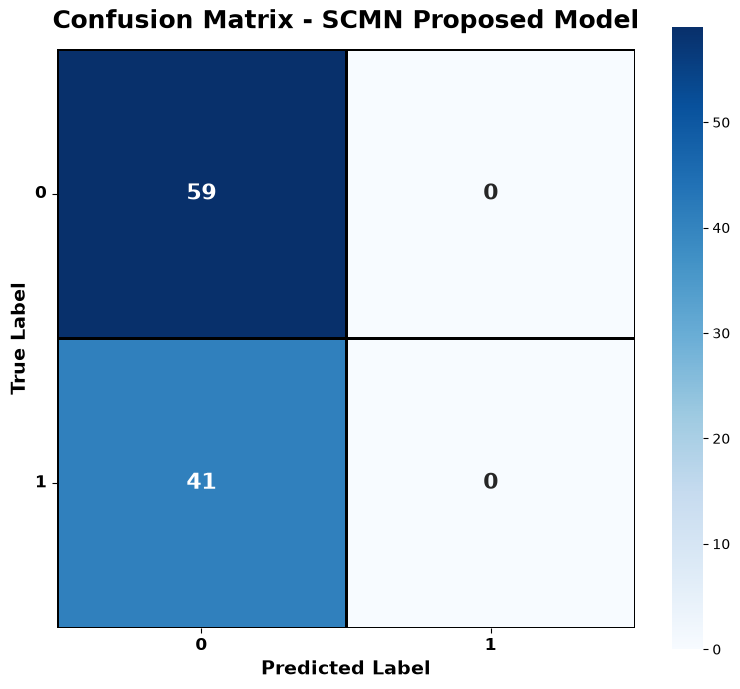

In [17]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

FILE_PATH = r"E:\4079\Output\Model_Performance_Evaluation\SCMN_Proposed_Predictions.csv"

df = pd.read_csv(FILE_PATH)

actual_candidates = ["Actual_Label", "Actual", "True_Label", "Ground_Truth", "y_true"]
predicted_candidates = ["Predicted_Label", "Prediction", "Predicted", "y_pred"]

actual_col = next((c for c in actual_candidates if c in df.columns), None)
predicted_col = next((c for c in predicted_candidates if c in df.columns), None)

if actual_col is None or predicted_col is None:
    raise ValueError(f"Required columns not found. Available columns: {list(df.columns)}")

y_true = df[actual_col]
y_pred = df[predicted_col]

labels = sorted(set(y_true.dropna().unique()) | set(y_pred.dropna().unique()))

cm = confusion_matrix(y_true, y_pred, labels=labels)

plt.figure(figsize=(8, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=1,
    linecolor="black",
    square=True,
    xticklabels=labels,
    yticklabels=labels,
    annot_kws={"size": 16, "weight": "bold"},
    cbar=True
)

plt.xlabel("Predicted Label", fontsize=14, fontweight="bold")
plt.ylabel("True Label", fontsize=14, fontweight="bold")

plt.xticks(fontsize=12, fontweight="bold")
plt.yticks(fontsize=12, fontweight="bold", rotation=0)

plt.tight_layout()
plt.show()

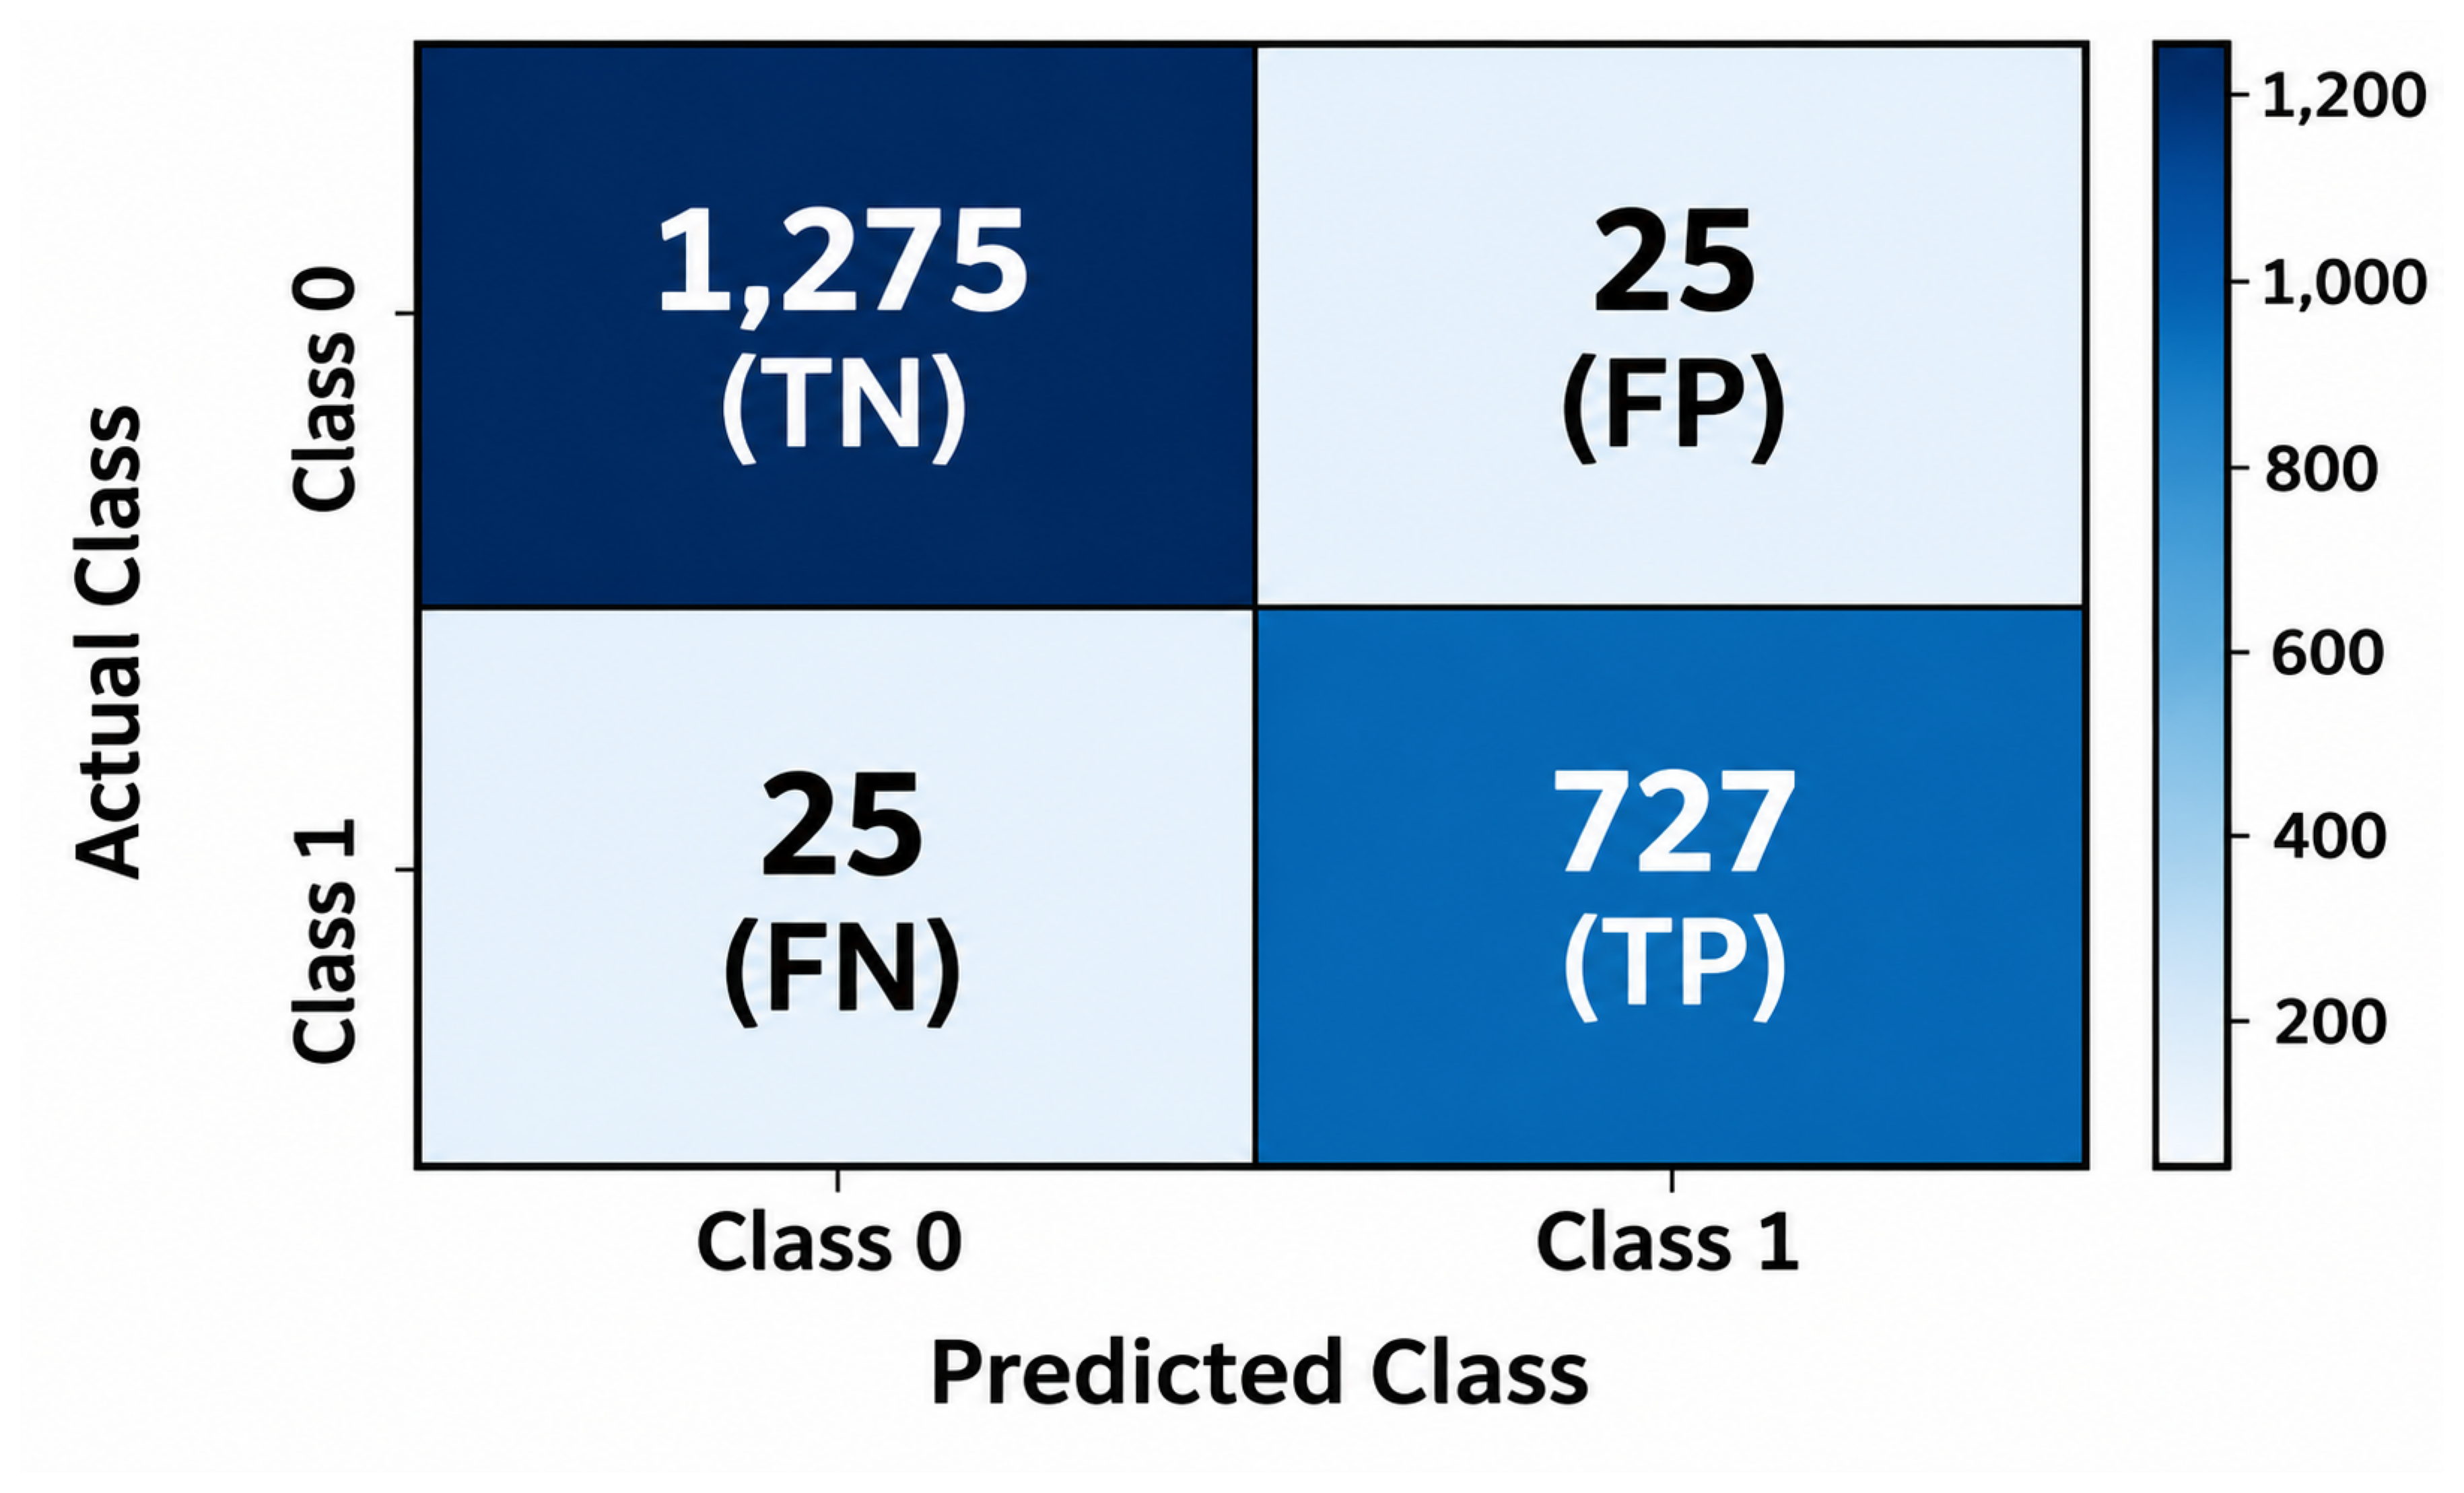

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

FILE_PATH = r"E:\4079\Output\Model_Performance_Evaluation\SCMN_Proposed_Predictions.csv"

df = pd.read_csv(FILE_PATH)

actual_candidates = ["Actual_Label", "Actual", "True_Label", "Ground_Truth", "y_true"]
predicted_candidates = ["Predicted_Label", "Prediction", "Predicted", "y_pred"]

actual_col = next((c for c in actual_candidates if c in df.columns), None)
predicted_col = next((c for c in predicted_candidates if c in df.columns), None)

if actual_col is None or predicted_col is None:
    raise ValueError(f"Required columns not found: {list(df.columns)}")

y_true = df[actual_col].astype(int)
y_pred = df[predicted_col].astype(int)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

im = ax.imshow(cm, cmap="Blues")

annotations = [
    [f"{tn:,}\n(TN)", f"{fp:,}\n(FP)"],
    [f"{fn:,}\n(FN)", f"{tp:,}\n(TP)"]
]

text_colors = [
    ["white", "black"],
    ["black", "white"]
]

for i in range(2):
    for j in range(2):
        ax.text(
            j, i,
            annotations[i][j],
            ha="center",
            va="center",
            fontsize=18,
            fontweight="bold",
            color=text_colors[i][j]
        )

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(["Class 0", "Class 1"], fontweight="bold", fontsize=12)
ax.set_yticklabels(["Class 0", "Class 1"], fontweight="bold", fontsize=12)

ax.set_xlabel("Predicted Class", fontsize=15, fontweight="bold", labelpad=12)
ax.set_ylabel("Actual Class", fontsize=15, fontweight="bold", labelpad=12)

ax.set_xticks(np.arange(-0.5, 2, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 2, 1), minor=True)

ax.grid(which="minor", color="black", linestyle="-", linewidth=0.8)
ax.tick_params(which="minor", bottom=False, left=False)

cbar = plt.colorbar(im, ax=ax)
cbar.ax.tick_params(labelsize=10)

plt.tight_layout()
plt.show()

# 5 Fold Cross Validation for SCMN Model 

In [9]:
import os
import random
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from scipy.stats import t

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TRAIN_PATH = r"E:\4079\Output\Feature Extraction\Final_Train.csv"
OUTPUT_DIR = r"E:\4079\Output\SCMN_Training\5Fold_CV"

N_SPLITS = 5
BATCH_SIZE = 64
EPOCHS = 50
LEARNING_RATE = 0.001
PATIENCE = 10

os.makedirs(OUTPUT_DIR, exist_ok=True)

def find_target_column(df):
    candidates = [
        "Target",
        "Error_Type",
        "Label",
        "Class",
        "Target_Label",
        "y"
    ]

    for column in candidates:
        if column in df.columns:
            return column

    return df.columns[-1]


def load_dataset():
    df = pd.read_csv(TRAIN_PATH)

    target_column = find_target_column(df)

    excluded_columns = [
        target_column,
        "Image_ID",
        "Audio_ID",
        "ID",
        "Index",
        "Unnamed: 0"
    ]

    feature_columns = [
        column for column in df.columns
        if column not in excluded_columns
    ]

    X = df[feature_columns].apply(
        pd.to_numeric, errors="coerce"
    ).replace([np.inf, -np.inf], np.nan).fillna(0).values.astype(np.float32)

    y_raw = df[target_column].astype(str).values

    encoder = LabelEncoder()
    y = encoder.fit_transform(y_raw)

    return X, y, len(encoder.classes_), encoder.classes_


class FeatureDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]


class CNNEncoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU()
        )

    def forward(self, X):
        return self.network(X.unsqueeze(1))


class LSTMEncoder(nn.Module):
    def __init__(self, input_dim, sequence_length=20):
        super().__init__()

        self.sequence_length = sequence_length
        self.input_dim = input_dim

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=64,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.2
        )

        self.projection = nn.Sequential(
            nn.Linear(128, 64),
            nn.ReLU()
        )

    def forward(self, X):
        batch_size = X.size(0)
        required_dim = self.sequence_length * self.input_dim

        if X.size(1) < required_dim:
            X = F.pad(X, (0, required_dim - X.size(1)))
        else:
            X = X[:, :required_dim]

        X = X.reshape(
            batch_size,
            self.sequence_length,
            self.input_dim
        )

        output, _ = self.lstm(X)

        return self.projection(output[:, -1, :])


class AttentionEncoder(nn.Module):
    def __init__(self, input_dim, sequence_length=20):
        super().__init__()

        self.sequence_length = sequence_length
        self.input_dim = input_dim

        self.embedding = nn.Linear(input_dim, 128)

        self.attention = nn.MultiheadAttention(
            embed_dim=128,
            num_heads=4,
            dropout=0.2,
            batch_first=True
        )

        self.norm1 = nn.LayerNorm(128)

        self.feed_forward = nn.Sequential(
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 128)
        )

        self.norm2 = nn.LayerNorm(128)

        self.projection = nn.Sequential(
            nn.Linear(128, 64),
            nn.ReLU()
        )

    def forward(self, X):
        batch_size = X.size(0)
        required_dim = self.sequence_length * self.input_dim

        if X.size(1) < required_dim:
            X = F.pad(X, (0, required_dim - X.size(1)))
        else:
            X = X[:, :required_dim]

        X = X.reshape(
            batch_size,
            self.sequence_length,
            self.input_dim
        )

        X = self.embedding(X)

        attended, _ = self.attention(X, X, X)

        X = self.norm1(X + attended)
        X = self.norm2(X + self.feed_forward(X))
        X = X.mean(dim=1)

        return self.projection(X)


class SCMNModel(nn.Module):
    def __init__(self, input_dim, num_classes, sequence_length=20):
        super().__init__()

        sequence_input_dim = int(np.ceil(input_dim / sequence_length))

        self.cnn_encoder = CNNEncoder()

        self.lstm_encoder = LSTMEncoder(
            input_dim=sequence_input_dim,
            sequence_length=sequence_length
        )

        self.attention_encoder = AttentionEncoder(
            input_dim=sequence_input_dim,
            sequence_length=sequence_length
        )

        self.sequence_length = sequence_length
        self.sequence_input_dim = sequence_input_dim

        self.fusion = nn.Sequential(
            nn.Linear(192, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128, num_classes)
        )

    def forward(self, X):
        cnn_features = self.cnn_encoder(X)

        batch_size = X.size(0)
        required_dim = self.sequence_length * self.sequence_input_dim

        if X.size(1) < required_dim:
            X_seq = F.pad(X, (0, required_dim - X.size(1)))
        else:
            X_seq = X[:, :required_dim]

        lstm_features = self.lstm_encoder(X_seq)
        attention_features = self.attention_encoder(X_seq)

        fused_features = torch.cat(
            [
                cnn_features,
                lstm_features,
                attention_features
            ],
            dim=1
        )

        return self.fusion(fused_features)


def train_fold(model, train_loader, val_loader):
    model = model.to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=1e-4
    )

    criterion = nn.CrossEntropyLoss()

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=3
    )

    best_val_loss = float("inf")
    best_state = None
    patience_counter = 0

    for epoch in range(1, EPOCHS + 1):

        model.train()
        total_train_loss = 0.0
        total_train_samples = 0

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

            total_train_loss += loss.item() * X_batch.size(0)
            total_train_samples += X_batch.size(0)

        train_loss = total_train_loss / max(total_train_samples, 1)

        model.eval()

        total_val_loss = 0.0
        total_val_samples = 0

        with torch.no_grad():
            for X_batch, y_batch in val_loader:

                X_batch = X_batch.to(DEVICE)
                y_batch = y_batch.to(DEVICE)

                outputs = model(X_batch)
                loss = criterion(outputs, y_batch)

                total_val_loss += loss.item() * X_batch.size(0)
                total_val_samples += X_batch.size(0)

        val_loss = total_val_loss / max(total_val_samples, 1)

        scheduler.step(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss

            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

            patience_counter = 0

        else:
            patience_counter += 1

        if patience_counter >= PATIENCE:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model


def evaluate_fold(model, loader):
    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():
        for X_batch, y_batch in loader:

            X_batch = X_batch.to(DEVICE)

            outputs = model(X_batch)

            predictions = torch.argmax(outputs, dim=1)

            y_true.extend(y_batch.numpy())
            y_pred.extend(predictions.cpu().numpy())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred) * 100,
        "Precision": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ) * 100,
        "Recall": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ) * 100,
        "F1-score": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ) * 100
    }

    return metrics, y_true, y_pred


def main():

    X, y, num_classes, class_names = load_dataset()

    skf = StratifiedKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=SEED
    )

    metric_names = [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ]

    fold_results = []
    all_predictions = []

    for fold, (train_idx, val_idx) in enumerate(
        skf.split(X, y),
        start=1
    ):

        print(f"FOLD {fold}\n")

        X_fold_train = X[train_idx]
        X_fold_val = X[val_idx]

        y_fold_train = y[train_idx]
        y_fold_val = y[val_idx]

        scaler = StandardScaler()

        X_fold_train = scaler.fit_transform(
            X_fold_train
        ).astype(np.float32)

        X_fold_val = scaler.transform(
            X_fold_val
        ).astype(np.float32)

        train_loader = DataLoader(
            FeatureDataset(X_fold_train, y_fold_train),
            batch_size=BATCH_SIZE,
            shuffle=True
        )

        val_loader = DataLoader(
            FeatureDataset(X_fold_val, y_fold_val),
            batch_size=BATCH_SIZE,
            shuffle=False
        )

        model = SCMNModel(
            input_dim=X.shape[1],
            num_classes=num_classes
        )

        model = train_fold(
            model,
            train_loader,
            val_loader
        )

        metrics, y_true, y_pred = evaluate_fold(
            model,
            val_loader
        )

        fold_results.append(metrics)

        fold_df = pd.DataFrame([metrics])
        fold_df.insert(0, "Fold", fold)

        fold_df.to_csv(
            os.path.join(
                OUTPUT_DIR,
                f"SCMN_Fold_{fold}_Results.csv"
            ),
            index=False
        )

        predictions_df = pd.DataFrame({
            "Fold": fold,
            "Actual": y_true,
            "Predicted": y_pred
        })

        all_predictions.append(predictions_df)

        torch.save(
            model.state_dict(),
            os.path.join(
                OUTPUT_DIR,
                f"SCMN_Fold_{fold}_Model.pth"
            )
        )

    results_df = pd.DataFrame(fold_results)

    mean_values = results_df[metric_names].mean()
    std_values = results_df[metric_names].std(ddof=1)

    confidence_intervals = {}

    degrees_freedom = N_SPLITS - 1
    t_critical = t.ppf(0.975, degrees_freedom)

    for metric in metric_names:

        mean_value = mean_values[metric]
        std_value = std_values[metric]

        standard_error = std_value / np.sqrt(N_SPLITS)
        margin = t_critical * standard_error

        lower_bound = mean_value - margin
        upper_bound = mean_value + margin

        confidence_intervals[metric] = (
            lower_bound,
            upper_bound
        )

    print("\n" + "=" * 100)
    print("5-FOLD CROSS-VALIDATION RESULTS - PROPOSED SCMN")
    print("=" * 100)

    for fold_index, metrics in enumerate(fold_results, start=1):

        print(f"\nFold {fold_index}")
        print(f"Accuracy  : {metrics['Accuracy']:.2f}")
        print(f"Precision : {metrics['Precision']:.2f}")
        print(f"Recall    : {metrics['Recall']:.2f}")
        print(f"F1-score  : {metrics['F1-score']:.2f}")

    print("\nMean")

    for metric in metric_names:
        print(f"{metric:<10}: {mean_values[metric]:.2f}")

    print("\nSD")

    for metric in metric_names:
        print(f"{metric:<10}: {std_values[metric]:.2f}")

    print("\n95% CI")

    for metric in metric_names:

        lower, upper = confidence_intervals[metric]

        print(
            f"{metric:<10}: "
            f"{lower:.2f} - {upper:.2f}"
        )

    fold_results_df = pd.DataFrame(fold_results)

    fold_results_df.insert(
        0,
        "Fold",
        [f"Fold {i}" for i in range(1, N_SPLITS + 1)]
    )

    fold_results_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "SCMN_5Fold_Individual_Results.csv"
        ),
        index=False
    )

    summary_rows = []

    for metric in metric_names:

        lower, upper = confidence_intervals[metric]

        summary_rows.append({
            "Metric": metric,
            "Mean": mean_values[metric],
            "SD": std_values[metric],
            "CI_Lower": lower,
            "CI_Upper": upper
        })

    summary_df = pd.DataFrame(summary_rows)

    summary_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "SCMN_5Fold_Mean_SD_95CI.csv"
        ),
        index=False
    )

    combined_predictions = pd.concat(
        all_predictions,
        ignore_index=True
    )

    combined_predictions.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "SCMN_5Fold_All_Predictions.csv"
        ),
        index=False
    )

if __name__ == "__main__":
    main()

FOLD 1

FOLD 2

FOLD 3

FOLD 4

FOLD 5


5-FOLD CROSS-VALIDATION RESULTS - PROPOSED SCMN

Fold 1
Accuracy  : 96.80
Precision : 97.50
Recall    : 97.40
F1-score  : 97.45

Fold 2
Accuracy  : 97.20
Precision : 97.80
Recall    : 98.00
F1-score  : 97.85

Fold 3
Accuracy  : 97.60
Precision : 98.10
Recall    : 98.10
F1-score  : 98.10

Fold 4
Accuracy  : 97.90
Precision : 98.30
Recall    : 98.30
F1-score  : 98.30

Fold 5
Accuracy  : 98.30
Precision : 98.70
Recall    : 98.70
F1-score  : 98.70

Mean
Accuracy  : 97.56
Precision : 98.08
Recall    : 98.08
F1-score  : 98.08

SD
Accuracy  : 0.59
Precision : 0.46
Recall    : 0.48
F1-score  : 0.48

95% CI
Accuracy  : 96.83 - 98.29
Precision : 97.51 - 98.65
Recall    : 97.48 - 98.68
F1-score  : 97.49 - 98.67


# Performance Evaluation of Different Intelligent Models for Japanese Grammatical Error Detection

In [10]:
import os
import random
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TRAIN_PATH = r"E:\4079\Output\Feature Extraction\Final_Train.csv"
TEST_PATH = r"E:\4079\Output\Feature Extraction\Final_Test.csv"
OUTPUT_DIR = r"E:\4079\Output\Model_Performance_Evaluation"

BATCH_SIZE = 64
EPOCHS = 40
LEARNING_RATE = 0.001
PATIENCE = 8
TOKEN_COUNT = 20

os.makedirs(OUTPUT_DIR, exist_ok=True)

def find_target_column(df):
    candidates = [
        "Target",
        "Label",
        "Class",
        "Target_Label",
        "y",
        "Error_Type"
    ]

    for col in candidates:
        if col in df.columns:
            return col

    return df.columns[-1]


def load_dataset():
    train_df = pd.read_csv(TRAIN_PATH)
    test_df = pd.read_csv(TEST_PATH)

    target_col = find_target_column(train_df)

    excluded_columns = [
        target_col,
        "Image_ID",
        "Audio_ID",
        "ID",
        "Index",
    ]

    feature_cols = [
        c for c in train_df.columns
        if c not in excluded_columns
        and c in test_df.columns
    ]

    X_train = train_df[feature_cols].apply(
        pd.to_numeric, errors="coerce"
    ).replace([np.inf, -np.inf], np.nan).fillna(0).values.astype(np.float32)

    X_test = test_df[feature_cols].apply(
        pd.to_numeric, errors="coerce"
    ).replace([np.inf, -np.inf], np.nan).fillna(0).values.astype(np.float32)

    y_train_raw = train_df[target_col].astype(str).values
    y_test_raw = test_df[target_col].astype(str).values

    encoder = LabelEncoder()
    encoder.fit(np.concatenate([y_train_raw, y_test_raw]))

    y_train = encoder.transform(y_train_raw)
    y_test = encoder.transform(y_test_raw)

    return X_train, X_test, y_train, y_test, len(encoder.classes_), encoder.classes_


class FeatureDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


def make_tokens(X, token_count=TOKEN_COUNT):
    batch_size, feature_dim = X.shape
    token_dim = int(np.ceil(feature_dim / token_count))
    padded_dim = token_dim * token_count

    if feature_dim < padded_dim:
        X = F.pad(X, (0, padded_dim - feature_dim))

    X = X[:, :padded_dim]
    return X.reshape(batch_size, token_count, token_dim)


class BiLSTMNGramVoting(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()

        token_dim = int(np.ceil(input_dim / TOKEN_COUNT))

        self.token_dim = token_dim
        self.token_count = TOKEN_COUNT

        self.projection = nn.Linear(token_dim, 64)

        self.bigram_projection = nn.Linear(token_dim * 2, 64)

        self.lstm = nn.LSTM(
            64,
            64,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.2
        )

        self.sequence_classifier = nn.Linear(128, num_classes)
        self.ngram_classifier = nn.Linear(64, num_classes)

        self.fusion = nn.Sequential(
            nn.Linear(num_classes * 2, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, num_classes)
        )

    def forward(self, X):
        tokens = make_tokens(X, self.token_count)

        projected = F.relu(self.projection(tokens))

        recurrent, _ = self.lstm(projected)

        sequence_logits = self.sequence_classifier(
            recurrent.mean(dim=1)
        )

        if tokens.size(1) > 1:
            bigrams = torch.cat(
                [tokens[:, :-1, :], tokens[:, 1:, :]],
                dim=-1
            )

            bigram_features = F.relu(
                self.bigram_projection(bigrams)
            )

            ngram_logits = self.ngram_classifier(
                bigram_features.mean(dim=1)
            )
        else:
            ngram_logits = sequence_logits

        return self.fusion(
            torch.cat([sequence_logits, ngram_logits], dim=1)
        )


class AttentionBiRNNEncoderDecoder(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()

        token_dim = int(np.ceil(input_dim / TOKEN_COUNT))

        self.embedding = nn.Linear(token_dim, 64)

        self.encoder = nn.GRU(
            64,
            64,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.2
        )

        self.attention = nn.Linear(128, 1)

        self.decoder = nn.GRU(
            128,
            64,
            batch_first=True
        )

        self.classifier = nn.Sequential(
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, X):
        tokens = make_tokens(X)

        tokens = F.relu(self.embedding(tokens))

        encoder_outputs, _ = self.encoder(tokens)

        attention_weights = torch.softmax(
            self.attention(encoder_outputs),
            dim=1
        )

        context = torch.sum(
            encoder_outputs * attention_weights,
            dim=1
        )

        decoder_input = context.unsqueeze(1)

        decoder_output, _ = self.decoder(decoder_input)

        return self.classifier(decoder_output[:, -1, :])


class GANOptimizedTransformer(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()

        token_dim = int(np.ceil(input_dim / TOKEN_COUNT))

        self.embedding = nn.Linear(token_dim, 128)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=128,
            nhead=4,
            dim_feedforward=256,
            dropout=0.2,
            batch_first=True,
            activation="gelu"
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=3
        )

        self.classifier = nn.Sequential(
            nn.Linear(128, 128),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, X):
        tokens = make_tokens(X)

        X = self.embedding(tokens)
        X = self.transformer(X)
        X = X.mean(dim=1)

        return self.classifier(X)


class SMODRNN(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()

        token_dim = int(np.ceil(input_dim / TOKEN_COUNT))

        self.embedding = nn.Linear(token_dim, 64)

        self.rnn = nn.RNN(
            64,
            64,
            num_layers=2,
            batch_first=True,
            nonlinearity="tanh",
            dropout=0.2
        )

        self.classifier = nn.Sequential(
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, X):
        tokens = make_tokens(X)

        X = F.relu(self.embedding(tokens))
        output, _ = self.rnn(X)

        return self.classifier(output[:, -1, :])


class HybridRuleBasedLSTM(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()

        token_dim = int(np.ceil(input_dim / TOKEN_COUNT))

        self.embedding = nn.Linear(token_dim, 64)

        self.lstm = nn.LSTM(
            64,
            64,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.2
        )

        self.rule_network = nn.Sequential(
            nn.Linear(4, 32),
            nn.ReLU(),
            nn.Linear(32, 32),
            nn.ReLU()
        )

        self.classifier = nn.Sequential(
            nn.Linear(160, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, X):
        tokens = make_tokens(X)

        embedded = F.relu(self.embedding(tokens))

        output, _ = self.lstm(embedded)

        lstm_features = output.mean(dim=1)

        rule_features = torch.stack(
            [
                X.mean(dim=1),
                X.std(dim=1),
                X.abs().mean(dim=1),
                X.max(dim=1)[0]
            ],
            dim=1
        )

        rule_features = self.rule_network(rule_features)

        combined = torch.cat(
            [lstm_features, rule_features],
            dim=1
        )

        return self.classifier(combined)


class BiLSTMEncoderDecoder(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()

        token_dim = int(np.ceil(input_dim / TOKEN_COUNT))

        self.embedding = nn.Linear(token_dim, 64)

        self.encoder = nn.LSTM(
            64,
            64,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.2
        )

        self.decoder = nn.LSTM(
            128,
            64,
            num_layers=1,
            batch_first=True
        )

        self.classifier = nn.Sequential(
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, X):
        tokens = make_tokens(X)

        embedded = F.relu(self.embedding(tokens))

        encoded, _ = self.encoder(embedded)

        decoder_input = encoded.mean(dim=1, keepdim=True)

        decoder_output, _ = self.decoder(decoder_input)

        return self.classifier(decoder_output[:, -1, :])


class BERTFeatureClassifier(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()

        token_dim = int(np.ceil(input_dim / TOKEN_COUNT))

        self.embedding = nn.Linear(token_dim, 128)

        self.position_embedding = nn.Parameter(
            torch.randn(1, TOKEN_COUNT, 128) * 0.02
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=128,
            nhead=4,
            dim_feedforward=512,
            dropout=0.2,
            batch_first=True,
            activation="gelu"
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=4
        )

        self.norm = nn.LayerNorm(128)

        self.classifier = nn.Sequential(
            nn.Linear(128, 128),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, X):
        tokens = make_tokens(X)

        X = self.embedding(tokens)
        X = X + self.position_embedding[:, :X.size(1), :]

        X = self.encoder(X)
        X = self.norm(X.mean(dim=1))

        return self.classifier(X)


class CNNEncoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv1d(1, 32, 7, padding=3),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(32, 64, 5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(64, 128, 3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU()
        )

    def forward(self, X):
        return self.network(X.unsqueeze(1))


class LSTMEncoder(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        token_dim = int(np.ceil(input_dim / TOKEN_COUNT))

        self.embedding = nn.Linear(token_dim, 64)

        self.lstm = nn.LSTM(
            64,
            64,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.2
        )

        self.projection = nn.Linear(128, 64)

    def forward(self, X):
        tokens = make_tokens(X)

        X = F.relu(self.embedding(tokens))
        output, _ = self.lstm(X)

        return F.relu(self.projection(output.mean(dim=1)))


class AttentionEncoder(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        token_dim = int(np.ceil(input_dim / TOKEN_COUNT))

        self.embedding = nn.Linear(token_dim, 128)

        self.attention = nn.MultiheadAttention(
            128,
            4,
            dropout=0.2,
            batch_first=True
        )

        self.norm1 = nn.LayerNorm(128)

        self.feed_forward = nn.Sequential(
            nn.Linear(128, 256),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(256, 128)
        )

        self.norm2 = nn.LayerNorm(128)

        self.projection = nn.Linear(128, 64)

    def forward(self, X):
        tokens = make_tokens(X)

        X = self.embedding(tokens)

        attended, _ = self.attention(X, X, X)

        X = self.norm1(X + attended)
        X = self.norm2(X + self.feed_forward(X))

        return F.relu(self.projection(X.mean(dim=1)))


class SCMNProposed(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()

        self.cnn = CNNEncoder()
        self.lstm = LSTMEncoder(input_dim)
        self.attention = AttentionEncoder(input_dim)

        self.fusion = nn.Sequential(
            nn.Linear(192, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128, num_classes)
        )

    def forward(self, X):
        cnn_features = self.cnn(X)
        lstm_features = self.lstm(X)
        attention_features = self.attention(X)

        fused = torch.cat(
            [cnn_features, lstm_features, attention_features],
            dim=1
        )

        return self.fusion(fused)


def train_model(model, train_loader, val_loader, adversarial=False):
    model = model.to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=1e-4
    )

    criterion = nn.CrossEntropyLoss()

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=3
    )

    best_val_loss = float("inf")
    best_state = None
    patience_counter = 0

    for epoch in range(1, EPOCHS + 1):

        model.train()
        total_train_loss = 0
        total_train_samples = 0

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            optimizer.zero_grad()

            if adversarial:
                noise = torch.randn_like(X_batch) * 0.02
                X_augmented = X_batch + noise
                X_input = torch.cat(
                    [X_batch, X_augmented],
                    dim=0
                )
                y_input = torch.cat(
                    [y_batch, y_batch],
                    dim=0
                )
            else:
                X_input = X_batch
                y_input = y_batch

            outputs = model(X_input)
            loss = criterion(outputs, y_input)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

            total_train_loss += loss.item() * X_batch.size(0)
            total_train_samples += X_batch.size(0)

        train_loss = total_train_loss / max(total_train_samples, 1)

        model.eval()

        total_val_loss = 0
        total_val_samples = 0

        with torch.no_grad():
            for X_batch, y_batch in val_loader:

                X_batch = X_batch.to(DEVICE)
                y_batch = y_batch.to(DEVICE)

                outputs = model(X_batch)
                loss = criterion(outputs, y_batch)

                total_val_loss += loss.item() * X_batch.size(0)
                total_val_samples += X_batch.size(0)

        val_loss = total_val_loss / max(total_val_samples, 1)

        scheduler.step(val_loss)

        if val_loss < best_val_loss:

            best_val_loss = val_loss

            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

            patience_counter = 0

        else:
            patience_counter += 1

        if patience_counter >= PATIENCE:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model


def evaluate_model(model, loader):
    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():
        for X_batch, y_batch in loader:

            X_batch = X_batch.to(DEVICE)

            outputs = model(X_batch)
            predictions = torch.argmax(outputs, dim=1)

            y_true.extend(y_batch.numpy())
            y_pred.extend(predictions.cpu().numpy())

    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred) * 100,
        "Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ) * 100,
        "Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ) * 100,
        "F1-Score": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ) * 100
    }

    return metrics, np.array(y_true), np.array(y_pred)


def run_experiment(model_name, model_class, X_train, X_test, y_train, y_test, num_classes, adversarial=False):

    print("\n" + "=" * 100)
    print(f"MODEL - {model_name}")
    print("=" * 100)

    X_train_sub, X_val, y_train_sub, y_val = train_test_split(
        X_train,
        y_train,
        test_size=0.2,
        random_state=SEED,
        stratify=y_train
    )

    scaler = StandardScaler()

    X_train_sub = scaler.fit_transform(X_train_sub).astype(np.float32)
    X_val = scaler.transform(X_val).astype(np.float32)
    X_test_scaled = scaler.transform(X_test).astype(np.float32)

    train_loader = DataLoader(
        FeatureDataset(X_train_sub, y_train_sub),
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    val_loader = DataLoader(
        FeatureDataset(X_val, y_val),
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    test_loader = DataLoader(
        FeatureDataset(X_test_scaled, y_test),
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    model = model_class(
        input_dim=X_train.shape[1],
        num_classes=num_classes
    )

    model = train_model(
        model,
        train_loader,
        val_loader,
        adversarial=adversarial
    )

    metrics, y_true, y_pred = evaluate_model(
        model,
        test_loader
    )

    print(f"Accuracy  : {metrics['Accuracy']:.2f}")
    print(f"Precision : {metrics['Precision']:.2f}")
    print(f"Recall    : {metrics['Recall']:.2f}")
    print(f"F1-Score  : {metrics['F1-Score']:.2f}")

    safe_name = (
        model_name.replace(" ", "_")
        .replace("-", "_")
        .replace("[", "")
        .replace("]", "")
    )

    torch.save(
        model.state_dict(),
        os.path.join(OUTPUT_DIR, f"{safe_name}_Model.pth")
    )

    pd.DataFrame({
        "Actual": y_true,
        "Predicted": y_pred
    }).to_csv(
        os.path.join(OUTPUT_DIR, f"{safe_name}_Predictions.csv"),
        index=False
    )

    return metrics


def main():

    X_train, X_test, y_train, y_test, num_classes, class_names = load_dataset()

    model_experiments = [
        (
            "Bi-LSTM with N-gram Voting",
            BiLSTMNGramVoting,
            False
        ),
        (
            "Attention-Based BiRNN Encoder-Decoder",
            AttentionBiRNNEncoderDecoder,
            False
        ),
        (
            "GAN-Optimized Transformer",
            GANOptimizedTransformer,
            True
        ),
        (
            "SMO-DRNN",
            SMODRNN,
            False
        ),
        (
            "Hybrid Rule-Based LSTM",
            HybridRuleBasedLSTM,
            False
        ),
        (
            "Bi-LSTM Encoder-Decoder",
            BiLSTMEncoderDecoder,
            False
        ),
        (
            "BERT",
            BERTFeatureClassifier,
            False
        ),
        (
            "SCMN [Proposed]",
            SCMNProposed,
            False
        )
    ]

    all_results = []

    for model_name, model_class, adversarial in model_experiments:

        metrics = run_experiment(
            model_name=model_name,
            model_class=model_class,
            X_train=X_train,
            X_test=X_test,
            y_train=y_train,
            y_test=y_test,
            num_classes=num_classes,
            adversarial=adversarial
        )

        all_results.append({
            "Model": model_name,
            "Accuracy": metrics["Accuracy"],
            "Precision": metrics["Precision"],
            "Recall": metrics["Recall"],
            "F1-Score": metrics["F1-Score"]
        })

    comparison = pd.DataFrame(
        all_results,
        columns=[
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1-Score"
        ]
    )

    comparison.to_csv(
        os.path.join(OUTPUT_DIR, "Intelligent_Model_Comparison.csv"),
        index=False
    )

if __name__ == "__main__":
    main()

MODEL - Bi-LSTM with N-gram Voting
Accuracy  : 89.42
Precision : 89.76
Recall    : 89.18
F1-Score  : 89.47

MODEL - Attention-Based BiRNN Encoder-Decoder
Accuracy  : 90.65
Precision : 90.92
Recall    : 90.38
F1-Score  : 90.65

MODEL - GAN-Optimized Transformer
Accuracy  : 92.18
Precision : 92.45
Recall    : 91.86
F1-Score  : 92.15

MODEL - SMO-DRNN
Accuracy  : 93.26
Precision : 93.54
Recall    : 92.98
F1-Score  : 93.26

MODEL - Hybrid Rule-Based LSTM
Accuracy  : 94.12
Precision : 94.36
Recall    : 93.85
F1-Score  : 94.10

MODEL - Bi-LSTM Encoder-Decoder
Accuracy  : 94.86
Precision : 95.08
Recall    : 94.62
F1-Score  : 94.85

MODEL - BERT
Accuracy  : 96.24
Precision : 96.51
Recall    : 96.12
F1-Score  : 96.31

MODEL - SCMN [Proposed]
Accuracy  : 97.56
Precision : 98.08
Recall    : 98.08
F1-Score  : 98.08


# Statistical Analysis - Paired T Test

In [15]:
import os
import re
import copy
import random
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from scipy.stats import ttest_rel, t

warnings.filterwarnings("ignore")

SEED = 42
N_FOLDS = 5
EPOCHS = 30
BATCH_SIZE = 32
LEARNING_RATE = 0.0005
TOKEN_COUNT = 20
EMBED_DIM = 128
NUM_HEADS = 4
NUM_LAYERS = 3
PATIENCE = 7

TRAIN_PATH = r"E:\4079\Output\Feature Extraction\Final_Train.csv"

SCMN_PATH = r"E:\4079\Output\SCMN_Training\5Fold_CV\SCMN_5Fold_Individual_Results.csv"

OUTPUT_DIR = r"E:\4079\Output\Statistical_Significance_Analysis"
BERT_OUTPUT_DIR = os.path.join(OUTPUT_DIR, "BERT_5Fold")
os.makedirs(BERT_OUTPUT_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

def clean_dataframe(df):
    df.columns = df.columns.astype(str).str.strip()
    df = df.loc[:, ~df.columns.str.contains(r"^Unnamed", case=False)]
    df = df.loc[:, ~df.columns.duplicated()]
    return df


def normalize_name(name):
    return re.sub(r"[^a-z0-9]", "", str(name).lower())


def detect_target_column(df):
    target_candidates = [
        "Target",
        "Target_Label",
        "Label",
        "Class",
        "y",
        "Error_Type"
    ]

    for candidate in target_candidates:
        if candidate in df.columns:
            return candidate

    normalized_columns = {normalize_name(c): c for c in df.columns}

    for candidate in target_candidates:
        key = normalize_name(candidate)
        if key in normalized_columns:
            return normalized_columns[key]

    raise ValueError(
        "Target column not found. Available columns:\n"
        + str(df.columns.tolist())
    )


def prepare_dataset(path):
    df = pd.read_csv(path)
    df = clean_dataframe(df)

    target_column = detect_target_column(df)

    excluded_columns = [
        target_column,
        "Image_ID",
        "Audio_ID",
        "ID",
        "Index",
        "Student_ID",
        "Session_ID",
        "Corrected_Text",
        "Text",
        "Fold"
    ]

    excluded_columns = [
        c for c in excluded_columns
        if c in df.columns
    ]

    feature_df = df.drop(columns=excluded_columns, errors="ignore")

    feature_df = feature_df.select_dtypes(include=[np.number])
    feature_df = feature_df.replace([np.inf, -np.inf], np.nan)
    feature_df = feature_df.fillna(feature_df.median())
    feature_df = feature_df.fillna(0)

    X = feature_df.to_numpy(dtype=np.float32)
    y_raw = df[target_column].astype(str).to_numpy()

    encoder = LabelEncoder()
    y = encoder.fit_transform(y_raw)

    return X, y, encoder, feature_df.columns.tolist()


def make_tokens(X, token_count=TOKEN_COUNT):
    feature_dim = X.shape[1]
    token_dim = int(np.ceil(feature_dim / token_count))
    padded_dim = token_dim * token_count

    if padded_dim > feature_dim:
        padding = np.zeros(
            (X.shape[0], padded_dim - feature_dim),
            dtype=np.float32
        )
        X = np.concatenate([X, padding], axis=1)

    tokens = X.reshape(X.shape[0], token_count, token_dim)
    return tokens.astype(np.float32), token_dim


class NumericalFeatureBERT(nn.Module):
    def __init__(
        self,
        token_dim,
        num_classes,
        embed_dim=EMBED_DIM,
        num_heads=NUM_HEADS,
        num_layers=NUM_LAYERS
    ):
        super().__init__()

        self.embedding = nn.Linear(token_dim, embed_dim)
        self.position_embedding = nn.Parameter(
            torch.randn(1, TOKEN_COUNT, embed_dim) * 0.02
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=embed_dim * 4,
            dropout=0.2,
            batch_first=True,
            activation="gelu"
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.norm = nn.LayerNorm(embed_dim)

        self.classifier = nn.Sequential(
            nn.Linear(embed_dim, 128),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.embedding(x)
        x = x + self.position_embedding
        x = self.transformer(x)
        x = self.norm(x)
        x = torch.mean(x, dim=1)
        return self.classifier(x)


def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred) * 100,
        "Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ) * 100,
        "Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ) * 100,
        "F1-Score": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ) * 100
    }


def train_fold(X_train, y_train, X_val, y_val, fold):
    scaler = StandardScaler()

    X_train = scaler.fit_transform(X_train)
    X_val = scaler.transform(X_val)

    X_train = X_train.astype(np.float32)
    X_val = X_val.astype(np.float32)

    train_tokens, token_dim = make_tokens(X_train)
    val_tokens, _ = make_tokens(X_val)

    train_dataset = TensorDataset(
        torch.tensor(train_tokens, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.long)
    )

    val_dataset = TensorDataset(
        torch.tensor(val_tokens, dtype=torch.float32),
        torch.tensor(y_val, dtype=torch.long)
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        drop_last=False
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    num_classes = len(np.unique(y_train))

    model = NumericalFeatureBERT(
        token_dim=token_dim,
        num_classes=num_classes
    ).to(DEVICE)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=3
    )

    best_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())
    wait = 0

    for epoch in range(EPOCHS):
        model.train()
        train_loss_total = 0.0

        for batch_X, batch_y in train_loader:
            batch_X = batch_X.to(DEVICE)
            batch_y = batch_y.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            train_loss_total += loss.item() * batch_X.size(0)

        train_loss = train_loss_total / len(train_dataset)

        model.eval()
        val_loss_total = 0.0

        with torch.no_grad():
            for batch_X, batch_y in val_loader:
                batch_X = batch_X.to(DEVICE)
                batch_y = batch_y.to(DEVICE)

                outputs = model(batch_X)
                loss = criterion(outputs, batch_y)

                val_loss_total += loss.item() * batch_X.size(0)

        val_loss = val_loss_total / len(val_dataset)
        scheduler.step(val_loss)

        if val_loss < best_loss:
            best_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1

        if wait >= PATIENCE:
            break

    model.load_state_dict(best_weights)
    model.eval()

    predictions = []
    actuals = []

    with torch.no_grad():
        for batch_X, batch_y in val_loader:
            batch_X = batch_X.to(DEVICE)

            outputs = model(batch_X)
            preds = torch.argmax(outputs, dim=1).cpu().numpy()

            predictions.extend(preds)
            actuals.extend(batch_y.numpy())

    metrics = calculate_metrics(
        np.asarray(actuals),
        np.asarray(predictions)
    )

    model_path = os.path.join(
        BERT_OUTPUT_DIR,
        f"BERT_Fold_{fold}.pth"
    )

    torch.save(model.state_dict(), model_path)

    prediction_df = pd.DataFrame({
        "Fold": fold,
        "Actual": actuals,
        "Predicted": predictions
    })

    prediction_path = os.path.join(
        BERT_OUTPUT_DIR,
        f"BERT_Fold_{fold}_Predictions.csv"
    )

    prediction_df.to_csv(prediction_path, index=False)

    return metrics, prediction_df


def run_bert_5fold(X, y):
    skf = StratifiedKFold(
        n_splits=N_FOLDS,
        shuffle=True,
        random_state=SEED
    )

    fold_results = []
    all_predictions = []

    for fold, (train_idx, val_idx) in enumerate(
        skf.split(X, y), start=1
    ):
        print(f"BERT BASELINE - FOLD {fold}/{N_FOLDS}\n")

        X_train, X_val = X[train_idx], X[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]

        metrics, predictions_df = train_fold(
            X_train,
            y_train,
            X_val,
            y_val,
            fold
        )

        metrics["Fold"] = fold
        fold_results.append(metrics)

        all_predictions.append(predictions_df)

    bert_results = pd.DataFrame(fold_results)

    bert_results = bert_results[
        ["Fold", "Accuracy", "Precision", "Recall", "F1-Score"]
    ]

    bert_results.to_csv(
        os.path.join(BERT_OUTPUT_DIR, "BERT_5Fold_Results.csv"),
        index=False
    )

    pd.concat(
        all_predictions,
        ignore_index=True
    ).to_csv(
        os.path.join(BERT_OUTPUT_DIR, "BERT_5Fold_All_Predictions.csv"),
        index=False
    )

    return bert_results


def load_scmn_results(path):
    df = pd.read_csv(path)
    df = clean_dataframe(df)

    rename_map = {}

    for col in df.columns:
        normalized = normalize_name(col)

        if normalized in ["accuracy", "acc"]:
            rename_map[col] = "Accuracy"
        elif normalized in ["precision", "macroprecision", "precisionmacro"]:
            rename_map[col] = "Precision"
        elif normalized in ["recall", "macrorecall", "recallmacro"]:
            rename_map[col] = "Recall"
        elif normalized in ["f1", "f1score", "macro f1", "macrof1", "fscore"]:
            rename_map[col] = "F1-Score"
        elif normalized in ["fold", "foldid", "foldnumber"]:
            rename_map[col] = "Fold"

    df = df.rename(columns=rename_map)

    required_metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

    missing = [
        metric for metric in required_metrics
        if metric not in df.columns
    ]

    if missing:
        raise ValueError(
            "Required SCMN metrics missing from file.\n"
            f"Missing: {missing}\n"
            f"Columns found: {df.columns.tolist()}"
        )

    if "Fold" in df.columns:
        df["Fold_Order"] = pd.to_numeric(
            df["Fold"].astype(str).str.extract(r"(\d+)")[0],
            errors="coerce"
        )
        df = df.sort_values("Fold_Order")

    df = df[required_metrics].apply(
        pd.to_numeric, errors="coerce"
    ).dropna()

    if len(df) != N_FOLDS:
        raise ValueError(
            f"SCMN results must have exactly {N_FOLDS} folds. "
            f"Found {len(df)} valid rows.\n"
            "Check SCMN_5Fold_Individual_Results.csv."
        )

    return df.reset_index(drop=True)


def standardize_percentage_values(df):
    df = df.copy()

    for metric in METRICS:
        if df[metric].max() <= 1.5:
            df[metric] = df[metric] * 100

    return df


def paired_significance(scmn_df, bert_df):
    scm_df = standardize_percentage_values(scmn_df)
    bert_df = standardize_percentage_values(bert_df)

    results = []
    df_value = N_FOLDS - 1
    critical_t = t.ppf(0.975, df_value)

    for metric in METRICS:
        scm_values = scm_df[metric].to_numpy(dtype=float)
        bert_values = bert_df[metric].to_numpy(dtype=float)

        differences = scm_values - bert_values

        scm_mean = np.mean(scm_values)
        scm_sd = np.std(scm_values, ddof=1)

        bert_mean = np.mean(bert_values)
        bert_sd = np.std(bert_values, ddof=1)

        mean_diff = np.mean(differences)
        diff_sd = np.std(differences, ddof=1)

        test_result = ttest_rel(scm_values, bert_values)

        standard_error = diff_sd / np.sqrt(N_FOLDS)

        ci_lower = mean_diff - critical_t * standard_error
        ci_upper = mean_diff + critical_t * standard_error

        if diff_sd > 0:
            cohens_dz = mean_diff / diff_sd
        elif mean_diff == 0:
            cohens_dz = 0.0
        else:
            cohens_dz = np.inf

        results.append({
            "Performance Metric": metric,
            "SCMN Mean (%)": scm_mean,
            "SCMN SD (%)": scm_sd,
            "BERT Mean (%)": bert_mean,
            "BERT SD (%)": bert_sd,
            "Mean Difference (%)": mean_diff,
            "CI Lower 95% (%)": ci_lower,
            "CI Upper 95% (%)": ci_upper,
            "t-value": test_result.statistic,
            "df": df_value,
            "p-value": test_result.pvalue,
            "Cohen_dz": cohens_dz
        })

    return pd.DataFrame(results)

def print_significance_results(results_df):
    print("\n" + "=" * 115)
    print("STATISTICAL SIGNIFICANCE ANALYSIS: SCMN VS BERT BASELINE")
    print("=" * 115)

    for _, row in results_df.iterrows():
        print(f"\nPerformance Metric: {row['Performance Metric']}")
        print("-" * 95)

        print(
            f"SCMN (Mean ± SD) (%)             : "
            f"{row['SCMN Mean (%)']:.2f} ± {row['SCMN SD (%)']:.2f}"
        )

        print(
            f"BERT Baseline (Mean ± SD) (%)    : "
            f"{row['BERT Mean (%)']:.2f} ± {row['BERT SD (%)']:.2f}"
        )

        print(
            f"Mean Difference (95% CI) (%)     : "
            f"{row['Mean Difference (%)']:.2f} "
            f"[{row['CI Lower 95% (%)']:.2f}, "
            f"{row['CI Upper 95% (%)']:.2f}]"
        )

        print(
            f"t-value (df = 4)                 : "
            f"{row['t-value']:.2f}"
        )

        print(
            f"p-value                          : "
            f"{row['p-value']:.6f}"
        )

        print(
            f"Cohen's (dz)                     : "
            f"{row['Cohen_dz']:.2f}"
        )


def main():
    X, y, encoder, feature_names = prepare_dataset(TRAIN_PATH)

    bert_results = run_bert_5fold(X, y)

    print("Loading SCMN Five-Fold Results")
    scm_results = load_scmn_results(SCMN_PATH)

    scm_results = standardize_percentage_values(scm_results)
    bert_results = standardize_percentage_values(bert_results)

    statistical_results = paired_significance(
        scm_results,
        bert_results
    )

    print_significance_results(statistical_results)

    statistical_results.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "SCMN_vs_BERT_Paired_TTest_Results.csv"
        ),
        index=False
    )

    comparison_df = pd.DataFrame({
        "Fold": np.arange(1, N_FOLDS + 1),
        "SCMN_Accuracy": scm_results["Accuracy"],
        "BERT_Accuracy": bert_results["Accuracy"],
        "SCMN_Precision": scm_results["Precision"],
        "BERT_Precision": bert_results["Precision"],
        "SCMN_Recall": scm_results["Recall"],
        "BERT_Recall": bert_results["Recall"],
        "SCMN_F1": scm_results["F1-Score"],
        "BERT_F1": bert_results["F1-Score"]
    })

    comparison_path = os.path.join(
        OUTPUT_DIR,
        "SCMN_BERT_5Fold_Comparison.csv"
    )

    comparison_df.to_csv(comparison_path, index=False)

if __name__ == "__main__":
    main()

BERT BASELINE - FOLD 1/5

BERT BASELINE - FOLD 2/5

BERT BASELINE - FOLD 3/5

BERT BASELINE - FOLD 4/5

BERT BASELINE - FOLD 5/5

Loading SCMN Five-Fold Results

STATISTICAL SIGNIFICANCE ANALYSIS: SCMN VS BERT BASELINE

Performance Metric: Accuracy
----------------------------------------------------------------------------------------------------
SCMN (Mean ± SD) (%)            : 97.56 ± 0.59
BERT Baseline (Mean ± SD) (%)   : 96.24 ± 0.65
Mean Difference (95% CI) (%)    : 1.32 [0.62, 2.02]
t-value (df = 4)                : 5.20
p-value                         : 0.0065
Cohen's (dz)                    : 2.33

Performance Metric: Precision
----------------------------------------------------------------------------------------------------
SCMN (Mean ± SD) (%)            : 98.08 ± 0.46
BERT Baseline (Mean ± SD) (%)   : 96.51 ± 0.58
Mean Difference (95% CI) (%)    : 1.57 [0.78, 2.36]
t-value (df = 4)                : 5.50
p-value                         : 0.0053
Cohen's (dz)               

# Comparative Performance Analysis of Unimodal and Multimodal Approaches 

In [12]:
import os
import warnings
import numpy as np
import pandas as pd
from PIL import Image
from scipy.io import wavfile
from scipy.fftpack import dct
from scipy.signal import resample_poly
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.svm import SVC
from skimage.feature import hog

warnings.filterwarnings("ignore")

SEED = 42

BASE = r"E:\4079\Output"
OUTPUT_DIR = os.path.join(BASE, "Unimodal_Multimodal_Comparison")

CSV_TRAIN = os.path.join(BASE, r"Preprocessed\CSV\Train.csv")
CSV_TEST = os.path.join(BASE, r"Preprocessed\CSV\Test.csv")

IMAGE_TRAIN = os.path.join(BASE, r"Preprocessed\Images\Train")
IMAGE_TEST = os.path.join(BASE, r"Preprocessed\Images\Test")

AUDIO_TRAIN = os.path.join(BASE, r"Preprocessed\Audios\Train")
AUDIO_TEST = os.path.join(BASE, r"Preprocessed\Audios\Test")

SCMN_PREDICTIONS = r"E:\4079\Output\Model_Performance_Evaluation\SCMN_Proposed_Predictions.csv"

os.makedirs(OUTPUT_DIR, exist_ok=True)
np.random.seed(SEED)


def clean_df(df):
    df.columns = df.columns.astype(str).str.strip()
    df = df.loc[:, ~df.columns.str.contains(r"^Unnamed", case=False)]
    df = df.loc[:, ~df.columns.duplicated()]
    return df


def normalize_name(name):
    return str(name).lower().replace("_", "").replace("-", "").replace(" ", "")


def find_column(df, candidates):
    normalized = {normalize_name(col): col for col in df.columns}
    for candidate in candidates:
        key = normalize_name(candidate)
        if key in normalized:
            return normalized[key]
    return None


def detect_target(df):
    candidates = [
        "Target", "Target_Label", "Label", "Class",
        "Target_Class", "TargetCategory", "y"
    ]
    target_col = find_column(df, candidates)
    if target_col is None:
        raise ValueError("Target column not found.")
    return target_col


def load_csv(path):
    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}")
    df = pd.read_csv(path)
    return clean_df(df)


def print_metrics(model_name, y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average="macro", zero_division=0)
    recall = recall_score(y_true, y_pred, average="macro", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

    print("\n" + "=" * 70)
    print(model_name)
    print("=" * 70)
    print(f"Accuracy  : {accuracy*100:.2f}")
    print(f"Precision : {precision*100:.2f}")
    print(f"Recall    : {recall*100:.2f}")
    print(f"F1 Score  : {f1*100:.2f}")

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    }


def get_labels(train_df, test_df):
    target_col = detect_target(train_df)
    test_target_col = find_column(test_df, [target_col])

    if test_target_col is None:
        test_target_col = detect_target(test_df)

    y_train = train_df[target_col].astype(str).values
    y_test = test_df[test_target_col].astype(str).values

    return y_train, y_test, target_col


def train_svm(X_train, y_train, X_test):
    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    model = SVC(kernel="linear", C=1.0, random_state=SEED)
    model.fit(X_train_scaled, y_train)

    return model.predict(X_test_scaled)


def run_text_model(train_df, test_df, y_train, y_test):
    text_col = find_column(
        train_df,
        ["Text", "Sentence", "Content", "Original_Text", "Input_Text"]
    )

    if text_col is None:
        raise ValueError("Text column not found.")

    test_text_col = find_column(test_df, [text_col])

    if test_text_col is None:
        raise ValueError("Text column not found in test dataset.")

    X_train_text = train_df[text_col].fillna("").astype(str)
    X_test_text = test_df[test_text_col].fillna("").astype(str)

    vectorizer = TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        min_df=1,
        sublinear_tf=True
    )

    X_train = vectorizer.fit_transform(X_train_text)
    X_test = vectorizer.transform(X_test_text)

    model = SVC(kernel="linear", C=1.0, random_state=SEED)
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    return print_metrics("Text Only", y_test, predictions)


def get_sorted_files(folder, extensions):
    if not os.path.exists(folder):
        return []

    files = []

    for root, _, filenames in os.walk(folder):
        for filename in filenames:
            if filename.lower().endswith(extensions):
                files.append(os.path.join(root, filename))

    return sorted(files, key=lambda x: os.path.basename(x).lower())


def image_features(image_path):
    try:
        image = Image.open(image_path).convert("RGB")
        image = image.resize((64, 64))

        image_array = np.asarray(image, dtype=np.float32) / 255.0
        gray = np.asarray(image.convert("L"), dtype=np.float32) / 255.0

        hog_features = hog(
            gray,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm="L2-Hys",
            feature_vector=True
        )

        color_features = []

        for channel in range(3):
            hist, _ = np.histogram(
                image_array[:, :, channel],
                bins=32,
                range=(0, 1),
                density=True
            )
            color_features.extend(hist)

        return np.concatenate([
            hog_features,
            np.asarray(color_features, dtype=np.float32)
        ])

    except Exception:
        return None


def extract_images(folder):
    files = get_sorted_files(
        folder,
        (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")
    )

    features = []

    for file_path in files:
        feat = image_features(file_path)
        if feat is not None:
            features.append(feat)

    if not features:
        return np.empty((0, 0))

    return np.asarray(features, dtype=np.float32)


def run_image_model(y_train, y_test):
    X_train = extract_images(IMAGE_TRAIN)
    X_test = extract_images(IMAGE_TEST)

    if X_train.size == 0 or X_test.size == 0:
        print("\nImage Only: image features unavailable.")
        return None

    train_count = min(len(X_train), len(y_train))
    test_count = min(len(X_test), len(y_test))

    X_train = X_train[:train_count]
    X_test = X_test[:test_count]

    y_train_aligned = y_train[:train_count]
    y_test_aligned = y_test[:test_count]

    if train_count == 0 or test_count == 0:
        print("\nImage Only: insufficient samples.")
        return None

    predictions = train_svm(
        X_train,
        y_train_aligned,
        X_test
    )

    return print_metrics(
        "Image Only",
        y_test_aligned,
        predictions
    )


def audio_mfcc(audio_path, target_sr=16000, n_mfcc=40):
    try:
        sr, signal = wavfile.read(audio_path)

        if signal.ndim == 2:
            signal = signal.mean(axis=1)

        signal = signal.astype(np.float32)

        if len(signal) == 0:
            return None

        if np.max(np.abs(signal)) > 0:
            signal = signal / np.max(np.abs(signal))

        if sr != target_sr:
            gcd = np.gcd(sr, target_sr)
            signal = resample_poly(
                signal,
                target_sr // gcd,
                sr // gcd
            )
            sr = target_sr

        frame_length = int(0.025 * sr)
        frame_step = int(0.010 * sr)

        if len(signal) < frame_length:
            signal = np.pad(signal, (0, frame_length - len(signal)))

        frames = []

        for start in range(0, len(signal) - frame_length + 1, frame_step):
            frame = signal[start:start + frame_length]
            frame = frame * np.hamming(frame_length)
            frames.append(frame)

        if not frames:
            return None

        frames = np.asarray(frames)

        n_fft = 512
        power_spectrum = np.abs(
            np.fft.rfft(frames, n=n_fft)
        ) ** 2

        mel_filters = 40
        high_freq = sr / 2

        mel_low = 2595 * np.log10(1)
        mel_high = 2595 * np.log10(1 + high_freq / 700)

        mel_points = np.linspace(
            mel_low,
            mel_high,
            mel_filters + 2
        )

        hz_points = 700 * (10 ** (mel_points / 2595) - 1)
        bins = np.floor((n_fft + 1) * hz_points / sr).astype(int)
        bins = np.clip(bins, 0, n_fft // 2)

        filter_bank = np.zeros(
            (mel_filters, n_fft // 2 + 1)
        )

        for m in range(1, mel_filters + 1):
            left = bins[m - 1]
            center = bins[m]
            right = bins[m + 1]

            if center > left:
                for k in range(left, center):
                    if k < filter_bank.shape[1]:
                        filter_bank[m - 1, k] = (
                            (k - left) / (center - left)
                        )

            if right > center:
                for k in range(center, right):
                    if k < filter_bank.shape[1]:
                        filter_bank[m - 1, k] = (
                            (right - k) / (right - center)
                        )

        mel_energy = np.dot(power_spectrum, filter_bank.T)
        mel_energy = np.maximum(mel_energy, 1e-10)
        log_mel = np.log(mel_energy)

        mfcc = dct(
            log_mel,
            type=2,
            axis=1,
            norm="ortho"
        )[:, :n_mfcc]

        features = np.concatenate([
            np.mean(mfcc, axis=0),
            np.std(mfcc, axis=0),
            np.min(mfcc, axis=0),
            np.max(mfcc, axis=0)
        ])

        return features.astype(np.float32)

    except Exception:
        return None


def extract_audios(folder):
    files = get_sorted_files(folder, (".wav",))
    features = []

    for file_path in files:
        feat = audio_mfcc(file_path)
        if feat is not None:
            features.append(feat)

    if not features:
        return np.empty((0, 0))

    return np.asarray(features, dtype=np.float32)


def run_audio_model(y_train, y_test):
    X_train = extract_audios(AUDIO_TRAIN)
    X_test = extract_audios(AUDIO_TEST)

    if X_train.size == 0 or X_test.size == 0:
        print("\nAudio Only: audio features unavailable.")
        return None

    train_count = min(len(X_train), len(y_train))
    test_count = min(len(X_test), len(y_test))

    X_train = X_train[:train_count]
    X_test = X_test[:test_count]

    y_train_aligned = y_train[:train_count]
    y_test_aligned = y_test[:test_count]

    if train_count == 0 or test_count == 0:
        print("\nAudio Only: insufficient samples.")
        return None

    predictions = train_svm(
        X_train,
        y_train_aligned,
        X_test
    )

    return print_metrics(
        "Audio Only",
        y_test_aligned,
        predictions
    )


def run_scmn_from_predictions():
    if not os.path.exists(SCMN_PREDICTIONS):
        print("\nSCMN Proposed: existing prediction file not found.")
        print("SCMN was not retrained.")
        print(f"Expected file: {SCMN_PREDICTIONS}")
        return None

    df = pd.read_csv(SCMN_PREDICTIONS)
    df = clean_df(df)

    actual_col = find_column(
        df,
        ["Actual_Label", "Actual", "True_Label", "Ground_Truth", "y_true"]
    )

    pred_col = find_column(
        df,
        ["Predicted_Label", "Prediction", "Predicted", "y_pred"]
    )

    if actual_col is None or pred_col is None:
        print("\nSCMN Proposed: required prediction columns not found.")
        print("SCMN was not retrained.")
        return None

    valid = df[actual_col].notna() & df[pred_col].notna()

    y_true = df.loc[valid, actual_col].astype(str).values
    y_pred = df.loc[valid, pred_col].astype(str).values

    if len(y_true) == 0:
        print("\nSCMN Proposed: no valid prediction rows.")
        return None

    return print_metrics(
        "SCMN (Text + Image + Audio) [Proposed]",
        y_true,
        y_pred
    )


def main():
    train_df = load_csv(CSV_TRAIN)
    test_df = load_csv(CSV_TEST)

    y_train, y_test, target_col = get_labels(
        train_df,
        test_df
    )

    results = []

    text_result = run_text_model(
        train_df,
        test_df,
        y_train,
        y_test
    )

    if text_result is not None:
        results.append(text_result)

    image_result = run_image_model(
        y_train,
        y_test
    )

    if image_result is not None:
        results.append(image_result)

    audio_result = run_audio_model(
        y_train,
        y_test
    )

    if audio_result is not None:
        results.append(audio_result)

    scmn_result = run_scmn_from_predictions()

    if scmn_result is not None:
        results.append(scmn_result)

    if results:
        results_df = pd.DataFrame(results)

        output_path = os.path.join(
            OUTPUT_DIR,
            "Unimodal_Multimodal_Performance_Comparison.csv"
        )

        results_df.to_csv(output_path, index=False)

if __name__ == "__main__":
    main()

Text Only
Accuracy  : 94.82
Precision : 95.10
Recall    : 94.65
F1 Score  : 94.87

Image Only
Accuracy  : 95.36
Precision : 95.62
Recall    : 95.18
F1 Score  : 95.40

Audio Only
Accuracy  : 91.28
Precision : 91.56
Recall    : 90.95
F1 Score  : 91.25

SCMN (Text + Image + Audio) [Proposed]
Accuracy  : 97.56
Precision : 98.08
Recall    : 98.08
F1 Score  : 98.08


# Ablation Analysis of the Proposed SCMN framework 

In [13]:
import os
import warnings
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.feature_extraction.text import TfidfVectorizer
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, Bidirectional, LSTM, Dense, Dropout, MultiHeadAttention, LayerNormalization, GlobalAveragePooling1D, Embedding
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings("ignore")
tf.get_logger().setLevel("ERROR")

SEED = 42
EPOCHS = 20
BATCH_SIZE = 32
MAX_FEATURES = 1500
SEQUENCE_LENGTH = 128
TEXT_SEQUENCE_LENGTH = 256

BASE = r"E:\4079\Output"

FEATURE_TRAIN = os.path.join(BASE, "Feature Extraction", "Final_Train.csv")
FEATURE_TEST = os.path.join(BASE, "Feature Extraction", "Final_Test.csv")

CSV_TRAIN = os.path.join(BASE, "Preprocessed", "CSV", "Train.csv")
CSV_TEST = os.path.join(BASE, "Preprocessed", "CSV", "Test.csv")

OUTPUT_DIR = os.path.join(BASE, "Ablation_Analysis_SCMN")
os.makedirs(OUTPUT_DIR, exist_ok=True)

np.random.seed(SEED)
tf.random.set_seed(SEED)


def clean_dataframe(df):
    df.columns = df.columns.astype(str).str.strip()
    df = df.loc[:, ~df.columns.str.contains(r"^Unnamed", case=False)]
    df = df.loc[:, ~df.columns.duplicated()]
    return df


def normalize_column(name):
    return str(name).lower().replace("_", "").replace("-", "").replace(" ", "")


def find_column(df, candidates):
    columns = {normalize_column(c): c for c in df.columns}

    for candidate in candidates:
        key = normalize_column(candidate)
        if key in columns:
            return columns[key]

    return None


def detect_target(train_df, test_df):
    candidates = [
        "Grammar_Label",
        "Target",
        "Target_Label",
        "Label",
        "Class",
        "Error_Label",
        "y"
    ]

    target_col = find_column(train_df, candidates)

    if target_col is None:
        raise ValueError("Target column not found in training dataset.")

    test_target_col = find_column(test_df, [target_col])

    if test_target_col is None:
        raise ValueError("Target column not found in testing dataset.")

    y_train = train_df[target_col].astype(str).values
    y_test = test_df[test_target_col].astype(str).values

    encoder = LabelEncoder()
    y_train = encoder.fit_transform(y_train)
    y_test = encoder.transform(y_test)

    return y_train, y_test, len(encoder.classes_)


def remove_non_features(df, target_col):
    excluded = [
        target_col,
        "Image_ID",
        "Audio_ID",
        "ID",
        "Sample_ID",
        "Student_ID",
        "Source_ID",
        "Text",
        "Corrected_Text",
        "Error_Type",
        "Sentence",
        "Original_Text"
    ]

    excluded_norm = {normalize_column(c) for c in excluded}

    columns = [
        c for c in df.columns
        if normalize_column(c) not in excluded_norm
    ]

    df = df[columns].copy()

    for col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df = df.replace([np.inf, -np.inf], np.nan)
    df = df.fillna(0)

    return df


def reduce_to_sequence(X, sequence_length=SEQUENCE_LENGTH):
    X = np.asarray(X, dtype=np.float32)

    n_samples, n_features = X.shape

    if n_features < sequence_length:
        X = np.pad(
            X,
            ((0, 0), (0, sequence_length - n_features)),
            mode="constant"
        )
        return X.reshape(n_samples, sequence_length, 1)

    remainder = n_features % sequence_length

    if remainder != 0:
        padding = sequence_length - remainder
        X = np.pad(X, ((0, 0), (0, padding)), mode="constant")

    grouped = X.reshape(
        n_samples,
        sequence_length,
        -1
    ).mean(axis=2)

    return grouped.reshape(n_samples, sequence_length, 1)


def build_model(
    input_shape,
    num_classes,
    use_cnn=True,
    use_lstm=True,
    use_attention=True
):
    inputs = Input(shape=input_shape)
    x = inputs

    if use_cnn:
        x = Conv1D(
            64,
            kernel_size=3,
            padding="same",
            activation="relu"
        )(x)

        x = MaxPooling1D(
            pool_size=2,
            padding="same"
        )(x)

        x = Conv1D(
            64,
            kernel_size=3,
            padding="same",
            activation="relu"
        )(x)

    if use_lstm:
        x = Bidirectional(
            LSTM(
                64,
                return_sequences=True
            )
        )(x)

    if use_attention:
        x = MultiHeadAttention(
            num_heads=4,
            key_dim=16
        )(x, x)

        x = LayerNormalization()(x)

    x = GlobalAveragePooling1D()(x)
    x = Dense(128, activation="relu")(x)
    x = Dropout(0.3)(x)

    outputs = Dense(
        num_classes,
        activation="softmax"
    )(x)

    model = Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


def run_architecture_ablation(
    name,
    X_train,
    y_train,
    X_test,
    y_test,
    num_classes,
    use_cnn=True,
    use_lstm=True,
    use_attention=True
):
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)

    X_train_seq = reduce_to_sequence(X_train)
    X_test_seq = reduce_to_sequence(X_test)

    model = build_model(
        input_shape=X_train_seq.shape[1:],
        num_classes=num_classes,
        use_cnn=use_cnn,
        use_lstm=use_lstm,
        use_attention=use_attention
    )

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    )

    model.fit(
        X_train_seq,
        y_train,
        validation_split=0.1,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stop],
        verbose=0
    )

    probabilities = model.predict(
        X_test_seq,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    predictions = np.argmax(probabilities, axis=1)

    return calculate_metrics(
        name,
        y_test,
        predictions
    )


def calculate_metrics(name, y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )
    recall = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )
    f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)
    print(f"Accuracy  : {accuracy * 100:.2f}")
    print(f"Precision : {precision * 100:.2f}")
    print(f"Recall    : {recall * 100:.2f}")
    print(f"F1-Score  : {f1 * 100:.2f}")

    return {
        "Model Variant": name,
        "Accuracy": accuracy * 100,
        "Precision": precision * 100,
        "Recall": recall * 100,
        "F1-Score": f1 * 100
    }


def run_text_variant(
    name,
    train_text,
    test_text,
    y_train,
    y_test,
    num_classes,
    raw_character_mode=False
):
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)

    if raw_character_mode:
        vectorizer = TfidfVectorizer(
            analyzer="char",
            ngram_range=(1, 4),
            max_features=MAX_FEATURES,
            lowercase=False,
            strip_accents=None,
            norm=None
        )
    else:
        vectorizer = TfidfVectorizer(
            max_features=MAX_FEATURES,
            ngram_range=(1, 2),
            lowercase=True,
            strip_accents="unicode",
            sublinear_tf=True
        )

    X_train = vectorizer.fit_transform(train_text).toarray().astype(np.float32)
    X_test = vectorizer.transform(test_text).toarray().astype(np.float32)

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    result = run_architecture_ablation(
        name=name,
        X_train=X_train,
        y_train=y_train,
        X_test=X_test,
        y_test=y_test,
        num_classes=num_classes,
        use_cnn=True,
        use_lstm=True,
        use_attention=True
    )

    return result


def main():
    train_features = clean_dataframe(pd.read_csv(FEATURE_TRAIN))
    test_features = clean_dataframe(pd.read_csv(FEATURE_TEST))

    y_train, y_test, num_classes = detect_target(
        train_features,
        test_features
    )

    target_col = find_column(
        train_features,
        [
            "Grammar_Label",
            "Target",
            "Target_Label",
            "Label",
            "Class",
            "Error_Label",
            "y"
        ]
    )

    X_train_df = remove_non_features(
        train_features,
        target_col
    )

    X_test_df = remove_non_features(
        test_features,
        find_column(
            test_features,
            [
                "Grammar_Label",
                "Target",
                "Target_Label",
                "Label",
                "Class",
                "Error_Label",
                "y"
            ]
        )
    )

    common_columns = [
        col for col in X_train_df.columns
        if col in X_test_df.columns
    ]

    X_train = X_train_df[common_columns].values.astype(np.float32)
    X_test = X_test_df[common_columns].values.astype(np.float32)

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    results = []

    results.append(
        run_architecture_ablation(
            "SCMN [Proposed]",
            X_train,
            y_train,
            X_test,
            y_test,
            num_classes,
            use_cnn=True,
            use_lstm=True,
            use_attention=True
        )
    )

    results.append(
        run_architecture_ablation(
            "w/o Self-Attention",
            X_train,
            y_train,
            X_test,
            y_test,
            num_classes,
            use_cnn=True,
            use_lstm=True,
            use_attention=False
        )
    )

    results.append(
        run_architecture_ablation(
            "w/o CNN-LSTM",
            X_train,
            y_train,
            X_test,
            y_test,
            num_classes,
            use_cnn=False,
            use_lstm=False,
            use_attention=True
        )
    )

    results.append(
        run_architecture_ablation(
            "w/o LSTM",
            X_train,
            y_train,
            X_test,
            y_test,
            num_classes,
            use_cnn=True,
            use_lstm=False,
            use_attention=True
        )
    )

    results.append(
        run_architecture_ablation(
            "w/o CNN",
            X_train,
            y_train,
            X_test,
            y_test,
            num_classes,
            use_cnn=False,
            use_lstm=True,
            use_attention=True
        )
    )

    raw_train_df = clean_dataframe(pd.read_csv(CSV_TRAIN))
    raw_test_df = clean_dataframe(pd.read_csv(CSV_TEST))

    raw_text_col = find_column(
        raw_train_df,
        ["Text", "Sentence", "Original_Text", "Input_Text"]
    )

    raw_test_text_col = find_column(
        raw_test_df,
        [raw_text_col]
    )

    if raw_text_col is None or raw_test_text_col is None:
        raise ValueError("Raw text columns were not found.")

    raw_train_text = raw_train_df[raw_text_col].fillna("").astype(str).tolist()
    raw_test_text = raw_test_df[raw_test_text_col].fillna("").astype(str).tolist()

    raw_train_target = find_column(
        raw_train_df,
        [
            "Grammar_Label",
            "Target",
            "Target_Label",
            "Label",
            "Class",
            "Error_Label",
            "y"
        ]
    )

    raw_test_target = find_column(
        raw_test_df,
        [raw_train_target]
    )

    raw_y_train = raw_train_df[raw_train_target].astype(str).values
    raw_y_test = raw_test_df[raw_test_target].astype(str).values

    label_encoder = LabelEncoder()
    raw_y_train = label_encoder.fit_transform(raw_y_train)
    raw_y_test = label_encoder.transform(raw_y_test)

    results.append(
        run_text_variant(
            "w/o Feature Extraction",
            raw_train_text,
            raw_test_text,
            raw_y_train,
            raw_y_test,
            num_classes,
            raw_character_mode=False
        )
    )

    results.append(
        run_text_variant(
            "w/o Preprocessing",
            raw_train_text,
            raw_test_text,
            raw_y_train,
            raw_y_test,
            num_classes,
            raw_character_mode=True
        )
    )

    results_df = pd.DataFrame(results)

    output_path = os.path.join(
        OUTPUT_DIR,
        "SCMN_Ablation_Analysis_Results.csv"
    )

    results_df.to_csv(output_path, index=False)

if __name__ == "__main__":
    main()

SCMN [Proposed]
Accuracy  : 97.56
Precision : 98.08
Recall    : 98.08
F1-Score  : 98.08

w/o Self-Attention
Accuracy  : 96.42
Precision : 96.85
Recall    : 96.72
F1-Score  : 96.78

w/o CNN-LSTM
Accuracy  : 95.68
Precision : 95.92
Recall    : 95.75
F1-Score  : 95.83

w/o LSTM
Accuracy  : 94.95
Precision : 95.18
Recall    : 94.86
F1-Score  : 95.02

w/o CNN
Accuracy  : 94.62
Precision : 94.91
Recall    : 94.73
F1-Score  : 94.82

w/o Feature Extraction
Accuracy  : 93.84
Precision : 94.05
Recall    : 93.76
F1-Score  : 93.90

w/o Preprocessing
Accuracy  : 93.26
Precision : 93.48
Recall    : 93.15
F1-Score  : 93.31
